<a href="https://colab.research.google.com/github/sravyam230/quantium-data-analytics-sim/blob/main/Forage_Quantium_Data_Analytics_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chips category review: customer segments and trial store performance

Quantium Virtual Internship (Forage), Retail Strategy and Analytics, Tasks 1 to 3.

Quantium's retail analytics team is working for the Category Manager for chips. The client wants to understand who buys chips, how they buy, and whether the new trial store layout in stores 77, 86 and 88 should be rolled out. The findings feed the chip category strategy for the next half year.

**Outline**
1. Framing the problem
2. Data preparation and checks (Task 1)
3. Customer segments and purchasing behaviour (Task 1)
4. Trial store assessment against control stores (Task 2)
5. Findings and recommendations (Task 3)

The datasets are provided by Forage for simulation use only and are not included in this repository. Place `QVI_transaction_data.xlsx` and `QVI_purchase_behaviour.csv` in a `data/` folder before running.

## 1. Framing the problem

Before touching the data, the work needs three questions answered for Julia, the Category Manager:

- **Who spends on chips?** Segment customers by life stage and premium status, then compare total sales, customers, purchase frequency, basket size and price paid.
- **What drives each segment's spend?** Separate spend into the number of buyers, how often they buy, how many packs they take and the price per pack. Then look at which brands and pack sizes each segment prefers.
- **Did the trial layout work?** Compare stores 77, 86 and 88 with a matched control store each during February to April 2019, and test whether any uplift is real or within normal month-to-month variation.

Metrics are defined before the analysis so the numbers are comparable across segments and stores:

| Metric | Definition |
|---|---|
| Total sales | Sum of `TOT_SALES` |
| Share of sales | Segment sales divided by total sales |
| Customers | Distinct `LYLTY_CARD_NBR` buying chips |
| Transactions per customer | Distinct `TXN_ID` divided by customers |
| Units per customer | Sum of `PROD_QTY` divided by customers |
| Spend per customer | Total sales divided by customers |
| Average price per unit | Total sales divided by units |

### Setup

In [ ]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(readxl)
  library(scales)
})
theme_set(theme_minimal(base_size = 11))
dir.create("outputs", showWarnings = FALSE)

# Helpers used across sections
title_case <- function(x) gsub("(^|[ /])([a-z])", "\\1\\U\\2", tolower(x), perl = TRUE)
to_date <- function(ym) as.Date(paste0(ym, "01"), format = "%Y%m%d")

## 2. Data preparation and checks (Task 1)

### 2.1 Load the raw files

In [ ]:
tx_raw   <- read_excel("data/QVI_transaction_data.xlsx")
cust_raw <- read_csv("data/QVI_purchase_behaviour.csv", show_col_types = FALSE)

cat("Transactions:", nrow(tx_raw), "rows x", ncol(tx_raw), "columns\n")
cat("Customers:   ", nrow(cust_raw), "rows x", ncol(cust_raw), "columns\n")
glimpse(tx_raw)

Transactions: 264836 rows x 8 columns


Customers:    72637 rows x 3 columns


Rows: 264,836
Columns: 8
$ DATE           <dbl> 43390, 43599, 43605, 43329, 43330, 43604, 43601, 43601,…
$ STORE_NBR      <dbl> 1, 1, 1, 2, 2, 4, 4, 4, 5, 7, 7, 8, 9, 13, 19, 20, 20, …
$ LYLTY_CARD_NBR <dbl> 1000, 1307, 1343, 2373, 2426, 4074, 4149, 4196, 5026, 7…
$ TXN_ID         <dbl> 1, 348, 383, 974, 1038, 2982, 3333, 3539, 4525, 6900, 7…
$ PROD_NBR       <dbl> 5, 66, 61, 69, 108, 57, 16, 24, 42, 52, 16, 114, 15, 92…
$ PROD_NAME      <chr> "Natural Chip        Compny SeaSalt175g", "CCs Nacho Ch…
$ PROD_QTY       <dbl> 2, 3, 2, 5, 3, 1, 1, 1, 1, 2, 1, 5, 2, 1, 1, 1, 4, 1, 1…
$ TOT_SALES      <dbl> 6.0, 6.3, 2.9, 15.0, 13.8, 5.1, 5.7, 3.6, 3.9, 7.2, 5.7…


### 2.2 Transaction data: formats, nulls and duplicates

`DATE` is stored as an Excel serial number, so it is converted using the Excel origin of 30 December 1899. The checks below look for nulls, duplicate rows and whether the date range is complete.

In [ ]:
tx <- tx_raw %>%
  mutate(DATE = if (is.numeric(DATE)) as.Date(DATE, origin = "1899-12-30") else as.Date(DATE))

cat("Data types:\n"); glimpse(tx)
cat("\nNulls per column:\n"); print(colSums(is.na(tx)))
cat("\nExact duplicate rows:", sum(duplicated(tx)), "\n")
cat("Date range:", format(min(tx$DATE)), "to", format(max(tx$DATE)), "\n")
cat("Distinct trading days:", n_distinct(tx$DATE), "\n")

missing_days <- setdiff(seq(as.Date("2018-07-01"), as.Date("2019-06-30"), by = "day"), unique(tx$DATE))
cat("Missing days:", format(as.Date(missing_days)), "\n")
summary(tx)

Data types:


Rows: 264,836
Columns: 8
$ DATE           <date> 2018-10-17, 2019-05-14, 2019-05-20, 2018-08-17, 2018-0…
$ STORE_NBR      <dbl> 1, 1, 1, 2, 2, 4, 4, 4, 5, 7, 7, 8, 9, 13, 19, 20, 20, …
$ LYLTY_CARD_NBR <dbl> 1000, 1307, 1343, 2373, 2426, 4074, 4149, 4196, 5026, 7…
$ TXN_ID         <dbl> 1, 348, 383, 974, 1038, 2982, 3333, 3539, 4525, 6900, 7…
$ PROD_NBR       <dbl> 5, 66, 61, 69, 108, 57, 16, 24, 42, 52, 16, 114, 15, 92…
$ PROD_NAME      <chr> "Natural Chip        Compny SeaSalt175g", "CCs Nacho Ch…
$ PROD_QTY       <dbl> 2, 3, 2, 5, 3, 1, 1, 1, 1, 2, 1, 5, 2, 1, 1, 1, 4, 1, 1…
$ TOT_SALES      <dbl> 6.0, 6.3, 2.9, 15.0, 13.8, 5.1, 5.7, 3.6, 3.9, 7.2, 5.7…



Nulls per column:


          DATE      STORE_NBR LYLTY_CARD_NBR         TXN_ID       PROD_NBR 
             0              0              0              0              0 
     PROD_NAME       PROD_QTY      TOT_SALES 
             0              0              0 



Exact duplicate rows: 1 


Date range: 2018-07-01 to 2019-06-30 


Distinct trading days: 364 


Missing days: 2018-12-25 


      DATE              STORE_NBR     LYLTY_CARD_NBR        TXN_ID       
 Min.   :2018-07-01   Min.   :  1.0   Min.   :   1000   Min.   :      1  
 1st Qu.:2018-09-30   1st Qu.: 70.0   1st Qu.:  70021   1st Qu.:  67602  
 Median :2018-12-30   Median :130.0   Median : 130358   Median : 135138  
 Mean   :2018-12-30   Mean   :135.1   Mean   : 135550   Mean   : 135158  
 3rd Qu.:2019-03-31   3rd Qu.:203.0   3rd Qu.: 203094   3rd Qu.: 202701  
 Max.   :2019-06-30   Max.   :272.0   Max.   :2373711   Max.   :2415841  
    PROD_NBR       PROD_NAME            PROD_QTY         TOT_SALES      
 Min.   :  1.00   Length:264836      Min.   :  1.000   Min.   :  1.500  
 1st Qu.: 28.00   Class :character   1st Qu.:  2.000   1st Qu.:  5.400  
 Median : 56.00   Mode  :character   Median :  2.000   Median :  7.400  
 Mean   : 56.58                      Mean   :  1.907   Mean   :  7.304  
 3rd Qu.: 85.00                      3rd Qu.:  2.000   3rd Qu.:  9.200  
 Max.   :114.00                      Max.   

There are no nulls, and the date range covers the full twelve months from July 2018 to June 2019. There are 364 trading days, so one day is missing. 25 December 2018 is the only gap, which fits stores being closed for Christmas. There is also one exact duplicate row, which is removed in section 2.4.

### 2.3 Product names: is every line a chip?

Product names are split into words, and words containing digits or symbols are removed. The most common remaining words show what the category contains.

In [ ]:
words <- tx %>%
  distinct(PROD_NAME) %>%
  pull(PROD_NAME) %>%
  str_split(" ") %>%
  unlist()
words <- words[!str_detect(words, "\\d|&|/") & words != ""]
words <- words %>% str_replace_all("[^A-Za-z]", "") %>% str_to_lower()
words <- words[words != ""]
word_counts <- sort(table(words), decreasing = TRUE)
print(head(word_counts, 40))

words
     chips     smiths    crinkle        cut     kettle     cheese       salt 
        21         16         14         14         13         12         12 
  original       chip    doritos      salsa       corn   pringles        rrd 
        10          9          9          9          8          8          8 
   chicken         ww        sea       sour     chilli     crisps     thinly 
         7          7          6          6          5          5          5 
     thins    vinegar      cream       deli  infuzions    natural        red 
         5          5          4          4          4          4          4 
      rock    supreme        ccs       cobs        dip         el       lime 
         4          4          3          3          3          3          3 
      mild        old       paso       popd sensations 
         3          3          3          3          3 


Most words are chip brands, flavours and chip types. The word *salsa* appears in several product names, so those lines are not chips. Nine salsa products are listed below and removed in section 2.4.

In [ ]:
salsa_products <- tx %>%
  filter(str_detect(str_to_lower(PROD_NAME), "salsa")) %>%
  distinct(PROD_NAME) %>%
  pull(PROD_NAME) %>%
  sort()
cat(length(salsa_products), "salsa products:\n")
cat(paste0("  ", salsa_products), sep = "\n")
cat("Salsa transaction lines:", sum(str_detect(str_to_lower(tx$PROD_NAME), "salsa")), "\n")

9 salsa products:


  Doritos Salsa       Medium 300g
  Doritos Salsa Mild  300g
  Old El Paso Salsa   Dip Chnky Tom Ht300g
  Old El Paso Salsa   Dip Tomato Med 300g
  Old El Paso Salsa   Dip Tomato Mild 300g
  Red Rock Deli SR    Salsa & Mzzrlla 150g
  Smiths Crinkle Cut  Tomato Salsa 150g
  Woolworths Medium   Salsa 300g
  Woolworths Mild     Salsa 300g


Salsa transaction lines: 18094 


### 2.4 Outliers and cleaning

Quantity is checked next. Most lines are one to three packs, but one customer bought 200 packs in a single transaction, twice. A customer buying chips at that scale looks like a commercial buyer rather than a retail shopper, so the card is reviewed before any decision is made.

In [ ]:
tx %>% count(PROD_QTY) %>% tail(6)

outlier_lines <- tx %>% filter(PROD_QTY >= 200)
outlier_lines %>%
  select(DATE, STORE_NBR, LYLTY_CARD_NBR, TXN_ID, PROD_NAME, PROD_QTY, TOT_SALES)

card <- outlier_lines$LYLTY_CARD_NBR[1]
cat("\nAll lines for card", card, ":\n")
tx %>% filter(LYLTY_CARD_NBR == card) %>% select(DATE, PROD_NAME, PROD_QTY, TOT_SALES)

PROD_QTY,n
<dbl>,<int>
1,27518
2,236039
3,430
4,397
5,450
200,2


DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NAME,PROD_QTY,TOT_SALES
<date>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>
2018-08-19,226,226000,226201,Dorito Corn Chp Supreme 380g,200,650
2019-05-20,226,226000,226210,Dorito Corn Chp Supreme 380g,200,650



All lines for card 226000 :


DATE,PROD_NAME,PROD_QTY,TOT_SALES
<date>,<chr>,<dbl>,<dbl>
2018-08-19,Dorito Corn Chp Supreme 380g,200,650
2019-05-20,Dorito Corn Chp Supreme 380g,200,650


Card 226000 has only these two transactions in the year, each for 200 packs and $650. That pattern does not match an ordinary shopper, so the card is excluded from the analysis. The duplicate line is also removed, since it has the same card, store, transaction, product, quantity and value as the line before it.

The cleaning steps are applied in a fixed order, and the number of rows removed at each step is recorded so the result can be reconciled.

In [ ]:
n0 <- nrow(tx)

tx <- tx %>% filter(!str_detect(str_to_lower(PROD_NAME), "salsa"))
n1 <- nrow(tx)

tx <- tx %>% filter(LYLTY_CARD_NBR != 226000)
n2 <- nrow(tx)

tx <- tx %>% distinct()
n3 <- nrow(tx)

clean_log <- tibble(
  step = c("Raw transaction lines", "Remove salsa products",
           "Remove commercial-scale card 226000", "Remove exact duplicate line"),
  rows_remaining = c(n0, n1, n2, n3),
  rows_removed = c(0, -diff(c(n0, n1, n2, n3)))
)
clean_log

step,rows_remaining,rows_removed
<chr>,<int>,<dbl>
Raw transaction lines,264836,0
Remove salsa products,246742,18094
Remove commercial-scale card 226000,246740,2
Remove exact duplicate line,246739,1


### 2.5 Feature engineering: pack size and brand

Pack size is the number before the letter *g* in the product name. Brand is the first word of the product name, with spelling variants merged. Brand names are checked after the mapping, so any mismatch is visible.

In [ ]:
brand_map <- c(DORITO = "DORITOS", GRAIN = "GRNWVES", INFZNS = "INFUZIONS", NCC = "NATURAL",
               RED = "RRD", SMITH = "SMITHS", SNBTS = "SUNBITES", WW = "WOOLWORTHS")

tx <- tx %>%
  mutate(
    PACK_SIZE = as.integer(str_match(PROD_NAME, "(\\d+)\\s*[gG]\\b")[, 2]),
    BRAND_RAW = str_to_upper(word(PROD_NAME, 1)),
    BRAND = if_else(BRAND_RAW %in% names(brand_map), unname(brand_map[BRAND_RAW]), BRAND_RAW)
  ) %>%
  select(-BRAND_RAW)

cat("Missing pack sizes:", sum(is.na(tx$PACK_SIZE)), "\n")
cat("Pack sizes (g):", sort(unique(tx$PACK_SIZE)), "\n")
cat("\nBrands:", n_distinct(tx$BRAND), "\n")
tx %>% count(BRAND, sort = TRUE) %>% print(n = Inf)

Missing pack sizes: 0 


Pack sizes (g): 70 90 110 125 134 135 150 160 165 170 175 180 190 200 210 220 250 270 330 380 



Brands: 20 


# A tibble: 20 × 2
   BRAND          n
   <chr>      <int>
 1 KETTLE     41288
 2 SMITHS     30352
 3 DORITOS    25224
 4 PRINGLES   25102
 5 RRD        16321
 6 INFUZIONS  14201
 7 THINS      14075
 8 WOOLWORTHS 11836
 9 COBS        9693
10 TOSTITOS    9471
11 TWISTIES    9454
12 GRNWVES     7740
13 NATURAL     7469
14 TYRRELLS    6442
15 CHEEZELS    4603
16 CCS         4551
17 SUNBITES    3008
18 CHEETOS     2927
19 BURGER      1564
20 FRENCH      1418


Pack sizes range from 70g to 380g, and every product name had a size. Brand names now have 20 distinct values. The remaining short names (for example *Burger* for Burger Rings and *French* for French Fries) are real product lines, so they are kept as they are.

A final check confirms that the unit price is plausible for every line.

In [ ]:
tx <- tx %>% mutate(UNIT_PRICE = TOT_SALES / PROD_QTY)
summary(tx$UNIT_PRICE)
cat("Max total sales on a single line:", max(tx$TOT_SALES), "\n")

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  1.320   3.000   3.800   3.832   4.600   6.500 

Max total sales on a single line: 29.5 


### 2.6 Customer data and merge

The customer file has one row per loyalty card. Each card is checked for duplicates and nulls, and the segment labels are reviewed before the merge.

In [ ]:
cat("Nulls:", sum(is.na(cust_raw)), "\n")
cat("Duplicate loyalty cards:", sum(duplicated(cust_raw$LYLTY_CARD_NBR)), "\n")
cat("\nLife stage:\n");       cust_raw %>% count(LIFESTAGE, sort = TRUE) %>% print(n = Inf)
cat("\nPremium customer:\n"); cust_raw %>% count(PREMIUM_CUSTOMER, sort = TRUE) %>% print(n = Inf)

Nulls: 0 


Duplicate loyalty cards: 0 



Life stage:


# A tibble: 7 × 2
  LIFESTAGE                  n
  <chr>                  <int>
1 RETIREES               14805
2 OLDER SINGLES/COUPLES  14609
3 YOUNG SINGLES/COUPLES  14441
4 OLDER FAMILIES          9780
5 YOUNG FAMILIES          9178
6 MIDAGE SINGLES/COUPLES  7275
7 NEW FAMILIES            2549



Premium customer:


# A tibble: 3 × 2
  PREMIUM_CUSTOMER     n
  <chr>            <int>
1 Mainstream       29245
2 Budget           24470
3 Premium          18922


In [ ]:
data <- tx %>%
  left_join(cust_raw, by = "LYLTY_CARD_NBR") %>%
  mutate(YEARMONTH = as.integer(year(DATE) * 100 + month(DATE)))

cat("Rows before merge:", nrow(tx), "\n")
cat("Rows after merge: ", nrow(data), "\n")
cat("Transaction lines with no customer match:", sum(is.na(data$LIFESTAGE)), "\n")
cat("Customers with no transactions in the year:",
    sum(!cust_raw$LYLTY_CARD_NBR %in% tx$LYLTY_CARD_NBR), "\n")

Rows before merge: 246739 


Rows after merge:  246739 


Transaction lines with no customer match: 0 


Customers with no transactions in the year: 1350 


Every transaction matched a customer, and the row count is unchanged after the left join, so no lines were duplicated. A small number of loyalty cards bought nothing during the year. They are kept in the customer file but do not affect any sales figures.

### 2.7 Save the cleaned files

The cleaned transaction and merged files are saved so the later sections and the report can reuse them.

In [ ]:
write_csv(tx, "outputs/QVI_transaction_clean.csv")
write_csv(data, "outputs/QVI_data.csv")
write_csv(clean_log, "outputs/cleaning_log.csv")
cat("Saved:", paste(list.files("outputs"), collapse = ", "), "\n")

Saved: QVI_data.csv, QVI_transaction_clean.csv, cleaning_log.csv 


### 2.8 Daily sales pattern

Transactions are counted per trading day to check whether the data behaves as expected over the year.

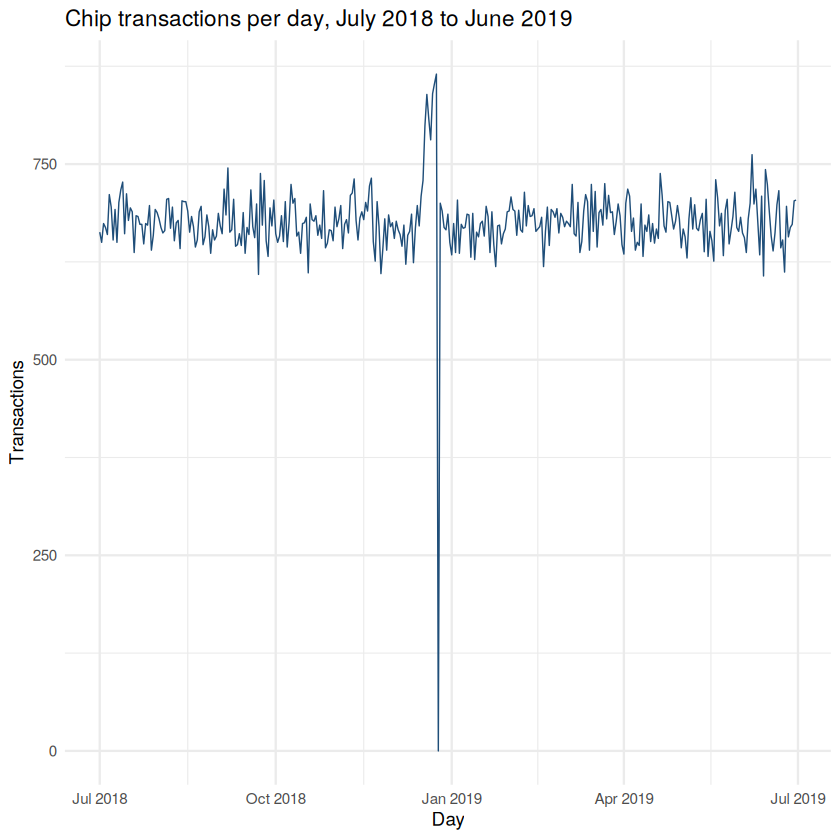

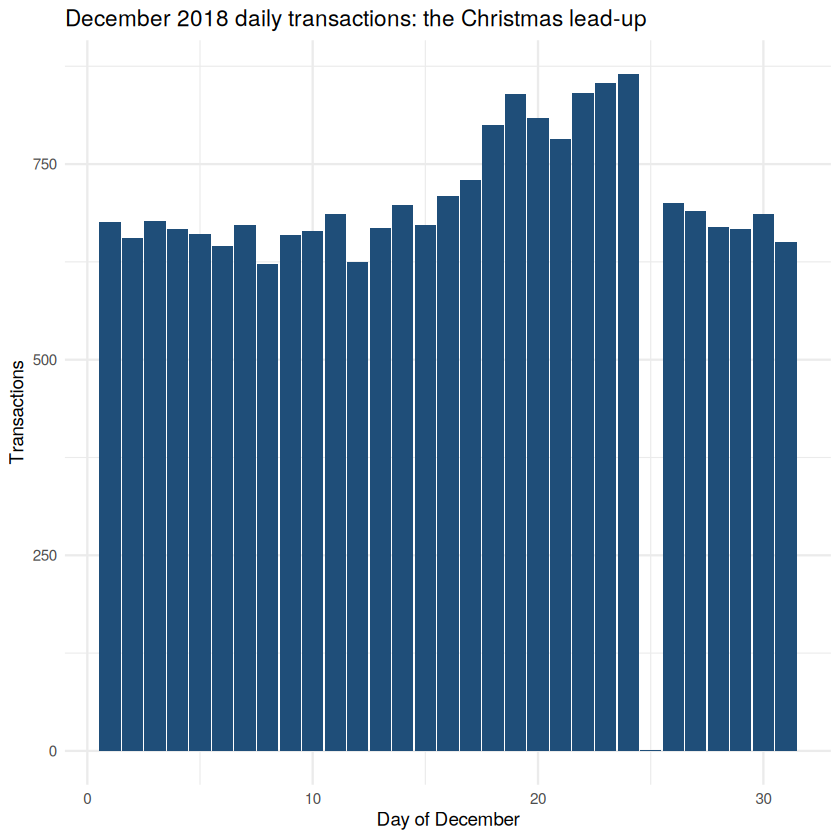

In [ ]:
daily <- data %>% count(DATE, name = "transactions")
daily <- tibble(DATE = seq(as.Date("2018-07-01"), as.Date("2019-06-30"), by = "day")) %>%
  left_join(daily, by = "DATE") %>%
  mutate(transactions = replace_na(transactions, 0))

p1 <- ggplot(daily, aes(DATE, transactions)) +
  geom_line(colour = "#1f4e79", linewidth = 0.3) +
  labs(title = "Chip transactions per day, July 2018 to June 2019", x = "Day", y = "Transactions")
print(p1)
ggsave("outputs/chart_01_daily_transactions.png", p1, width = 11, height = 4, dpi = 110)

dec <- daily %>% filter(year(DATE) == 2018, month(DATE) == 12)
p2 <- ggplot(dec, aes(day(DATE), transactions)) +
  geom_col(fill = "#1f4e79") +
  labs(title = "December 2018 daily transactions: the Christmas lead-up",
       x = "Day of December", y = "Transactions")
print(p2)
ggsave("outputs/chart_02_december_transactions.png", p2, width = 11, height = 4, dpi = 110)

Daily transactions are steady at roughly 650 to 700 a day through most of the year, including the first half of December. From about 17 December they climb to a peak of 865 on 24 December, the day before Christmas. Christmas Day has no transactions, which is consistent with stores being closed, so 25 December is the only missing trading day and it is a real closure rather than a data gap.

In [ ]:
segment_summary <- function(df, by = c("LIFESTAGE", "PREMIUM_CUSTOMER")) {
  df %>%
    group_by(across(all_of(by))) %>%
    summarise(
      sales = sum(TOT_SALES),
      customers = n_distinct(LYLTY_CARD_NBR),
      transactions = n_distinct(TXN_ID),
      units = sum(PROD_QTY),
      .groups = "drop"
    ) %>%
    mutate(
      sales_share = sales / sum(sales),
      customer_share = customers / sum(customers),
      txn_per_customer = transactions / customers,
      units_per_customer = units / customers,
      spend_per_customer = sales / customers,
      price_per_unit = sales / units
    ) %>%
    arrange(desc(sales))
}

segments <- segment_summary(data)
cat("Total sales:", round(sum(data$TOT_SALES), 2), "\n")
cat("Total customers buying chips:", n_distinct(data$LYLTY_CARD_NBR), "\n")
segments %>% mutate(across(where(is.double), ~ round(.x, 3)))

Total sales: 1805172 


Total customers buying chips: 71287 


LIFESTAGE,PREMIUM_CUSTOMER,sales,customers,transactions,units,sales_share,customer_share,txn_per_customer,units_per_customer,spend_per_customer,price_per_unit
<chr>,<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OLDER FAMILIES,Budget,156863.75,4611,21322,41853,0.087,0.065,4.624,9.077,34.019,3.748
YOUNG SINGLES/COUPLES,Mainstream,147582.20,7917,19482,36225,0.082,0.111,2.461,4.576,18.641,4.074
RETIREES,Mainstream,145168.95,6358,19878,37677,0.080,0.089,3.126,5.926,22.832,3.853
YOUNG FAMILIES,Budget,129717.95,3953,17629,34482,0.072,0.055,4.460,8.723,32.815,3.762
OLDER SINGLES/COUPLES,Budget,127833.60,4849,17078,32883,0.071,0.068,3.522,6.781,26.363,3.888
OLDER SINGLES/COUPLES,Mainstream,124648.50,4858,16958,32607,0.069,0.068,3.491,6.712,25.658,3.823
OLDER SINGLES/COUPLES,Premium,123531.55,4682,16472,31693,0.068,0.066,3.518,6.769,26.384,3.898
RETIREES,Budget,105916.30,4385,14147,26932,0.059,0.062,3.226,6.142,24.154,3.933
OLDER FAMILIES,Mainstream,96413.55,2788,13131,25804,0.053,0.039,4.710,9.255,34.582,3.736


### 3.2 Where are the sales coming from?

The first chart shows total sales by segment, which is the main view of where chip revenue sits.

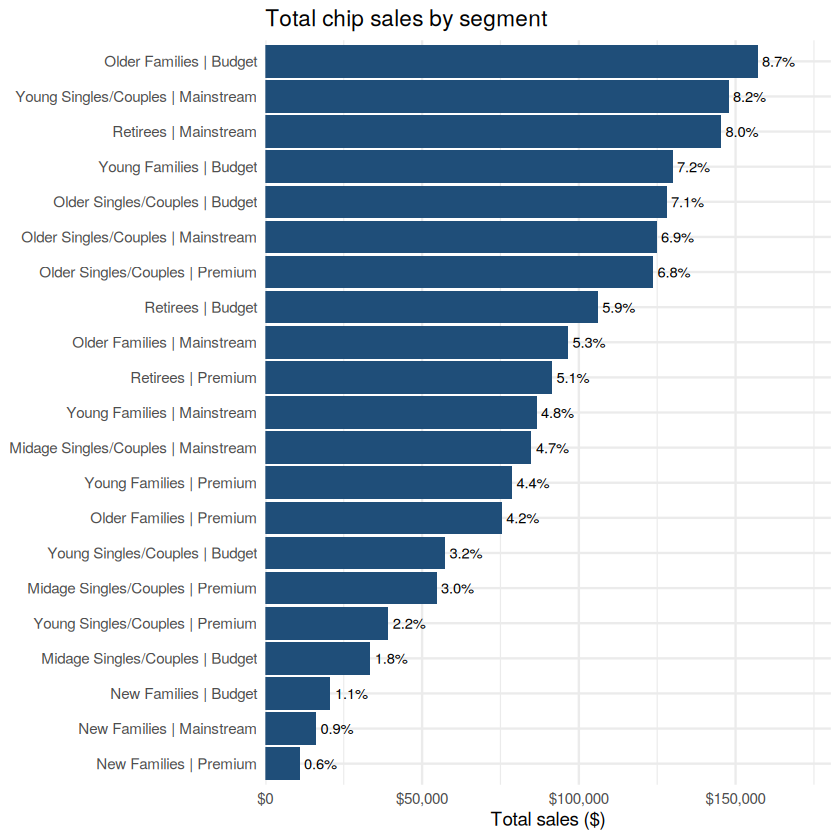

In [ ]:
seg_sales <- segments %>%
  mutate(segment = paste(title_case(LIFESTAGE), PREMIUM_CUSTOMER, sep = " | "))

p <- ggplot(seg_sales, aes(reorder(segment, sales), sales)) +
  geom_col(fill = "#1f4e79") +
  geom_text(aes(label = percent(sales_share, accuracy = 0.1)), hjust = -0.15, size = 3) +
  coord_flip() +
  scale_y_continuous(labels = dollar, expand = expansion(mult = c(0, 0.15))) +
  labs(title = "Total chip sales by segment", x = NULL, y = "Total sales ($)")
print(p)
ggsave("outputs/chart_03_sales_by_segment.png", p, width = 10, height = 7, dpi = 110)

Sales are spread widely across the segments rather than concentrated in one. The top three are Older Families (Budget), Young Singles/Couples (Mainstream) and Retirees (Mainstream). Together they account for about a quarter of chip sales, and no single segment exceeds 9% of the total.

### 3.3 Is higher spend driven by more buyers, more purchases, or bigger baskets?

A segment can sell more because it has more customers, buys more often, takes more packs per visit, or pays more per pack. The next charts separate these drivers.

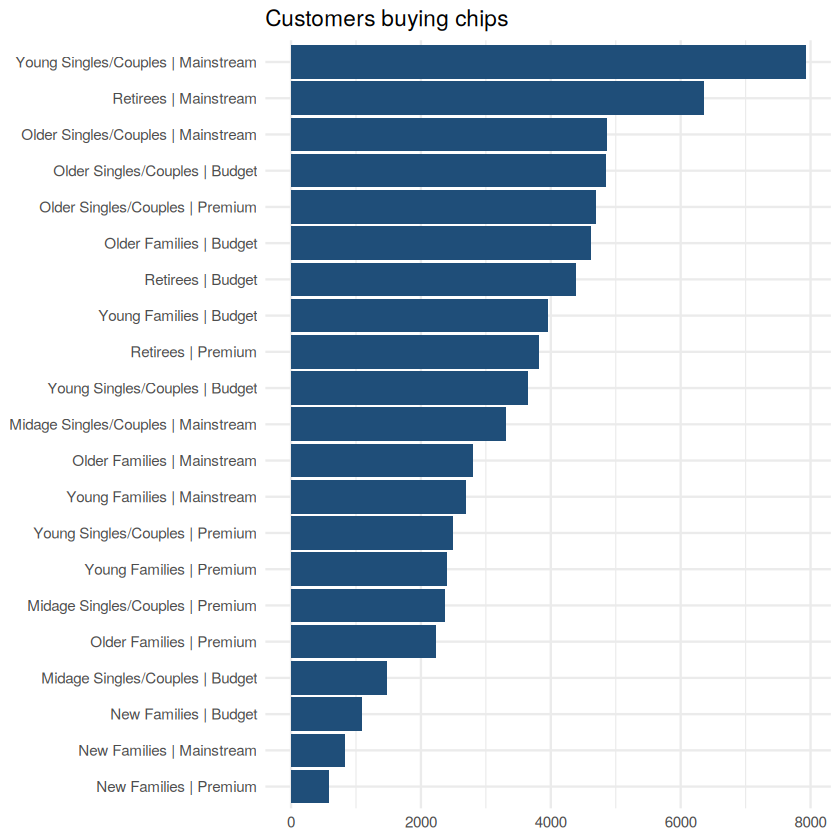

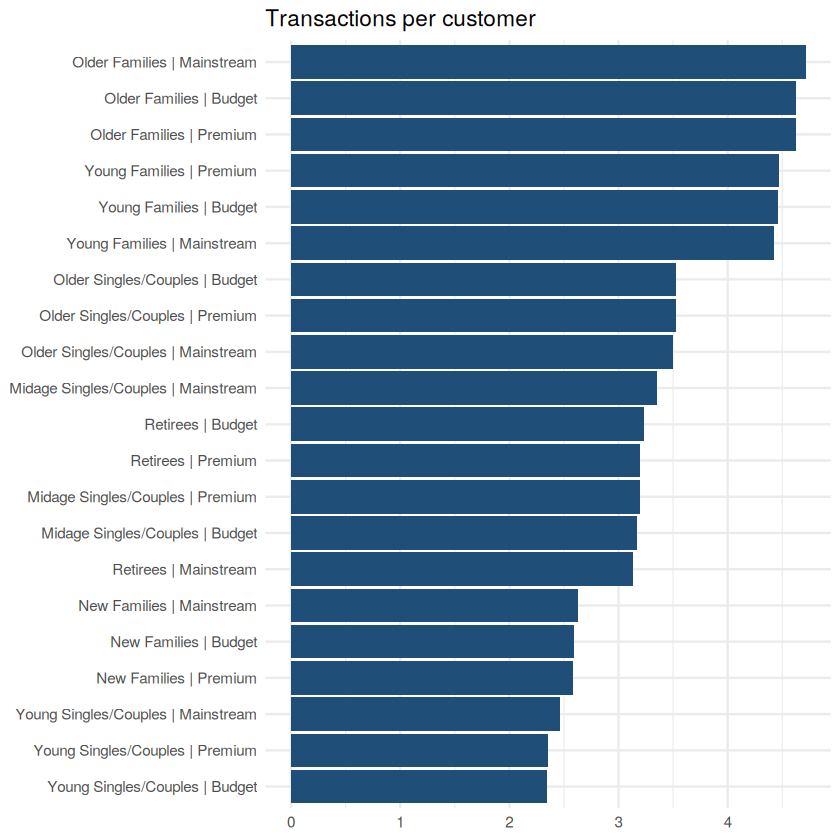

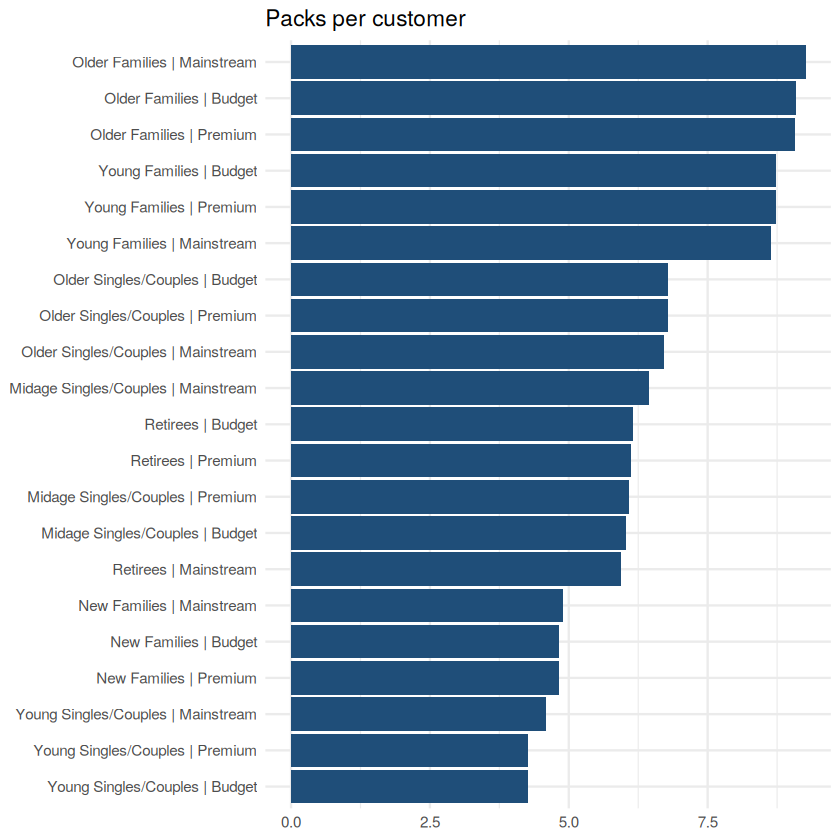

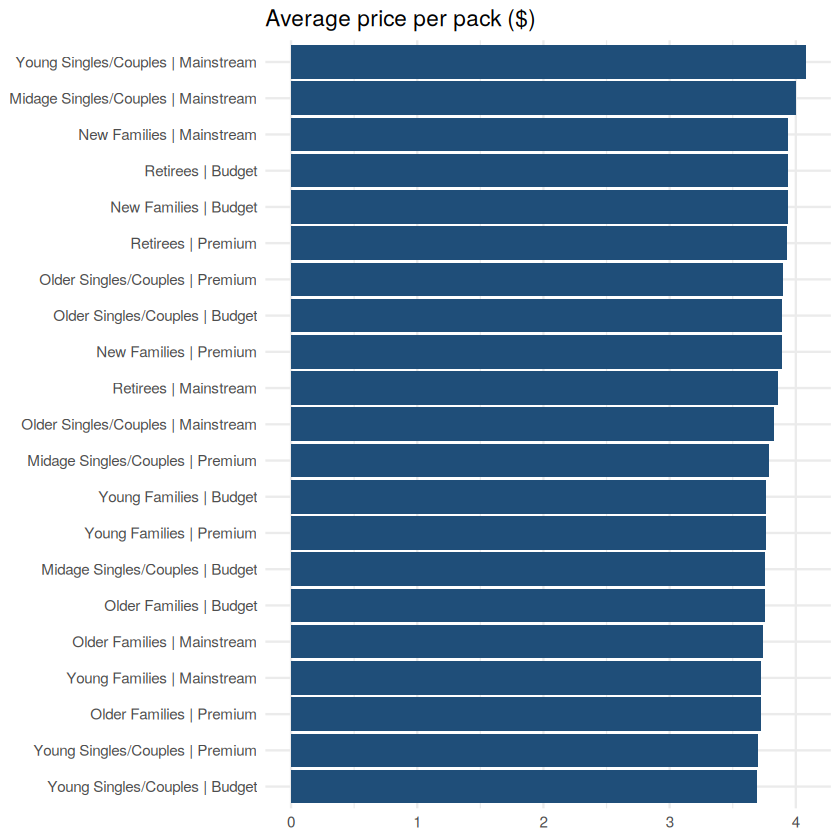

In [ ]:
driver_specs <- c(
  customers          = "Customers buying chips",
  txn_per_customer   = "Transactions per customer",
  units_per_customer = "Packs per customer",
  price_per_unit     = "Average price per pack ($)"
)

for (col in names(driver_specs)) {
  p <- ggplot(seg_sales, aes(reorder(segment, .data[[col]]), .data[[col]])) +
    geom_col(fill = "#1f4e79") +
    coord_flip() +
    labs(title = driver_specs[[col]], x = NULL, y = NULL)
  print(p)
  ggsave(paste0("outputs/chart_04_", col, ".png"), p, width = 9, height = 7, dpi = 110)
}

Two different drivers come out of this:

- **Families buy the most per visit.** Older and Young Families take roughly nine packs per customer, against about four to five for Young Singles/Couples. Their spend is driven by basket size rather than by how many of them shop.
- **Young Singles/Couples (Mainstream) are the largest group of buyers and pay the highest price, but visit least often.** They have the most customers of any segment and pay about $4.07 per pack, the highest of any segment. Their visits are infrequent (about 2.5 per customer over the year) and small (about 4.6 packs per customer).

Price per pack is fairly tight across segments, between about $3.69 and $4.07, so price is a secondary driver. Customer count and basket size explain most of the difference in sales.

### 3.4 Spend per customer

Spend per customer shows which segment is worth the most per shopper, not just in total.

LIFESTAGE,PREMIUM_CUSTOMER,sales,customers,spend_per_customer
<chr>,<chr>,<dbl>,<int>,<dbl>
OLDER FAMILIES,Mainstream,96413.55,2788,34.58
OLDER FAMILIES,Budget,156863.75,4611,34.02
OLDER FAMILIES,Premium,75242.60,2231,33.73
YOUNG FAMILIES,Budget,129717.95,3953,32.82
YOUNG FAMILIES,Premium,78571.70,2398,32.77


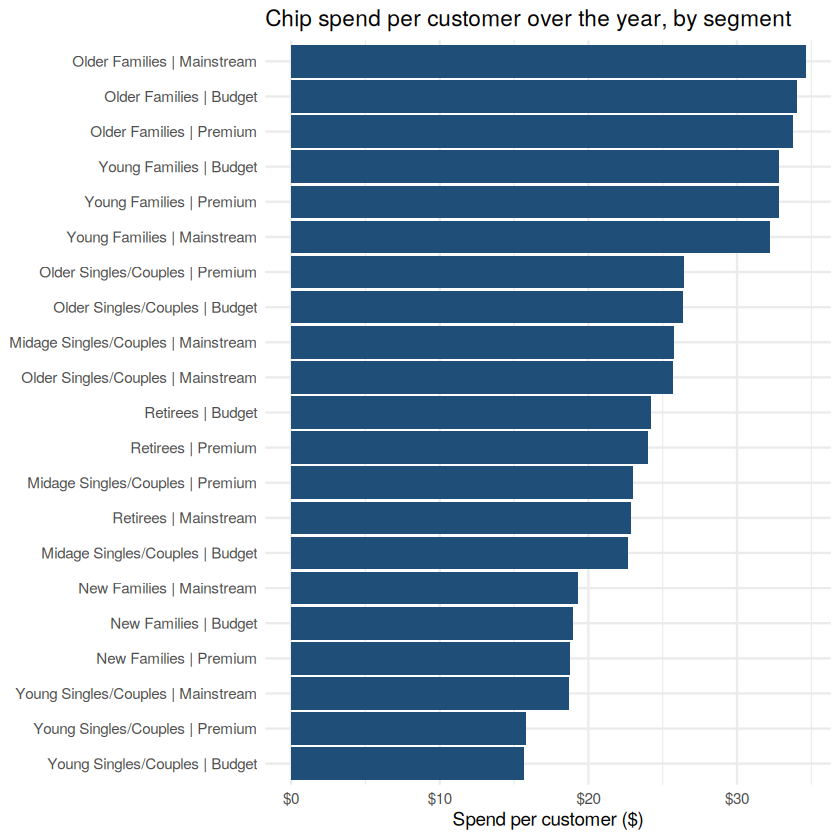

In [ ]:
p <- ggplot(seg_sales, aes(reorder(segment, spend_per_customer), spend_per_customer)) +
  geom_col(fill = "#1f4e79") +
  coord_flip() +
  scale_y_continuous(labels = dollar) +
  labs(title = "Chip spend per customer over the year, by segment", x = NULL, y = "Spend per customer ($)")
print(p)
ggsave("outputs/chart_05_spend_per_customer.png", p, width = 10, height = 7, dpi = 110)

segments %>%
  select(LIFESTAGE, PREMIUM_CUSTOMER, sales, customers, spend_per_customer) %>%
  arrange(desc(spend_per_customer)) %>%
  head(5) %>%
  mutate(across(where(is.double), ~ round(.x, 2)))

Spend per customer splits the segments into two groups. Family segments spend the most per customer, about $32 to $35, because they buy the most packs. Young Singles/Couples (Mainstream) are the largest group of buyers but spend the least per customer, about $19, so their total sales come from volume of shoppers rather than the size of each shop.

In [ ]:
cust_price <- data %>%
  group_by(LYLTY_CARD_NBR, LIFESTAGE, PREMIUM_CUSTOMER) %>%
  summarise(sales = sum(TOT_SALES), units = sum(PROD_QTY), .groups = "drop") %>%
  mutate(price_per_unit = sales / units)

singles <- cust_price %>%
  filter(LIFESTAGE %in% c("YOUNG SINGLES/COUPLES", "MIDAGE SINGLES/COUPLES"))
mainstream      <- singles %>% filter(PREMIUM_CUSTOMER == "Mainstream") %>% pull(price_per_unit)
budget_premium  <- singles %>% filter(PREMIUM_CUSTOMER != "Mainstream") %>% pull(price_per_unit)

cat(sprintf("Mainstream customers:         n=%s  mean price/pack $%.3f\n",
            format(length(mainstream), big.mark = ","), mean(mainstream)))
cat(sprintf("Budget and Premium customers: n=%s  mean price/pack $%.3f\n",
            format(length(budget_premium), big.mark = ","), mean(budget_premium)))

t.test(mainstream, budget_premium, var.equal = FALSE)

Mainstream customers:         n=11,215  mean price/pack $4.110


Budget and Premium customers: n=9,970  mean price/pack $3.673



	Welch Two Sample t-test

data:  mainstream and budget_premium
t = 37.94, df = 19169, p-value < 2.2e-16
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 0.4144535 0.4596103
sample estimates:
mean of x mean of y 
 4.109580  3.672548 


Mainstream singles and couples pay about $4.11 per pack on average, against about $3.67 for Budget and Premium. The difference is statistically significant (p well below 0.001), so it is not noise. Section 3.6 looks at which brands and pack sizes sit behind this price gap.

In [ ]:
is_target <- data$LIFESTAGE == "YOUNG SINGLES/COUPLES" & data$PREMIUM_CUSTOMER == "Mainstream"
target <- data[is_target, ]
rest   <- data[!is_target, ]

affinity <- function(col) {
  t_sh <- target %>%
    group_by(key = .data[[col]]) %>%
    summarise(t_qty = sum(PROD_QTY), .groups = "drop") %>%
    mutate(target_share = t_qty / sum(t_qty)) %>%
    select(key, target_share)
  r_sh <- rest %>%
    group_by(key = .data[[col]]) %>%
    summarise(r_qty = sum(PROD_QTY), .groups = "drop") %>%
    mutate(rest_share = r_qty / sum(r_qty)) %>%
    select(key, rest_share)
  full_join(t_sh, r_sh, by = "key") %>%
    replace_na(list(target_share = 0, rest_share = 0)) %>%
    mutate(affinity_index = target_share / rest_share) %>%
    arrange(desc(affinity_index))
}

brand_aff <- affinity("BRAND")
pack_aff  <- affinity("PACK_SIZE")

cat("Brands:\n"); brand_aff %>% mutate(across(where(is.double), ~ round(.x, 3))) %>% print(n = Inf)
cat("\nPack sizes:\n"); pack_aff %>% mutate(across(where(is.double), ~ round(.x, 3))) %>% print(n = Inf)

Brands:


# A tibble: 20 × 4
   key        target_share rest_share affinity_index
   <chr>             <dbl>      <dbl>          <dbl>
 1 TYRRELLS          0.032      0.026          1.23 
 2 TWISTIES          0.046      0.038          1.22 
 3 DORITOS           0.123      0.101          1.22 
 4 KETTLE            0.198      0.166          1.20 
 5 TOSTITOS          0.045      0.038          1.20 
 6 PRINGLES          0.119      0.101          1.19 
 7 COBS              0.045      0.039          1.14 
 8 INFUZIONS         0.065      0.057          1.13 
 9 THINS             0.06       0.057          1.06 
10 GRNWVES           0.033      0.031          1.05 
11 CHEEZELS          0.018      0.019          0.964
12 SMITHS            0.096      0.125          0.774
13 FRENCH            0.004      0.006          0.686
14 CHEETOS           0.008      0.012          0.666
15 RRD               0.044      0.067          0.649
16 NATURAL           0.02       0.031          0.635
17 CCS               0.011 


Pack sizes:


# A tibble: 20 × 4
     key target_share rest_share affinity_index
   <int>        <dbl>      <dbl>          <dbl>
 1   270        0.032      0.025          1.27 
 2   380        0.032      0.026          1.26 
 3   330        0.061      0.05           1.22 
 4   134        0.119      0.101          1.19 
 5   110        0.106      0.09           1.18 
 6   210        0.029      0.025          1.16 
 7   135        0.015      0.013          1.13 
 8   250        0.014      0.013          1.12 
 9   170        0.081      0.081          0.997
10   150        0.158      0.163          0.964
11   175        0.255      0.27           0.944
12   165        0.056      0.062          0.894
13   190        0.007      0.012          0.601
14   180        0.004      0.006          0.592
15   160        0.006      0.012          0.518
16    90        0.006      0.013          0.505
17   125        0.003      0.006          0.498
18   200        0.009      0.019          0.481
19    70        0.003

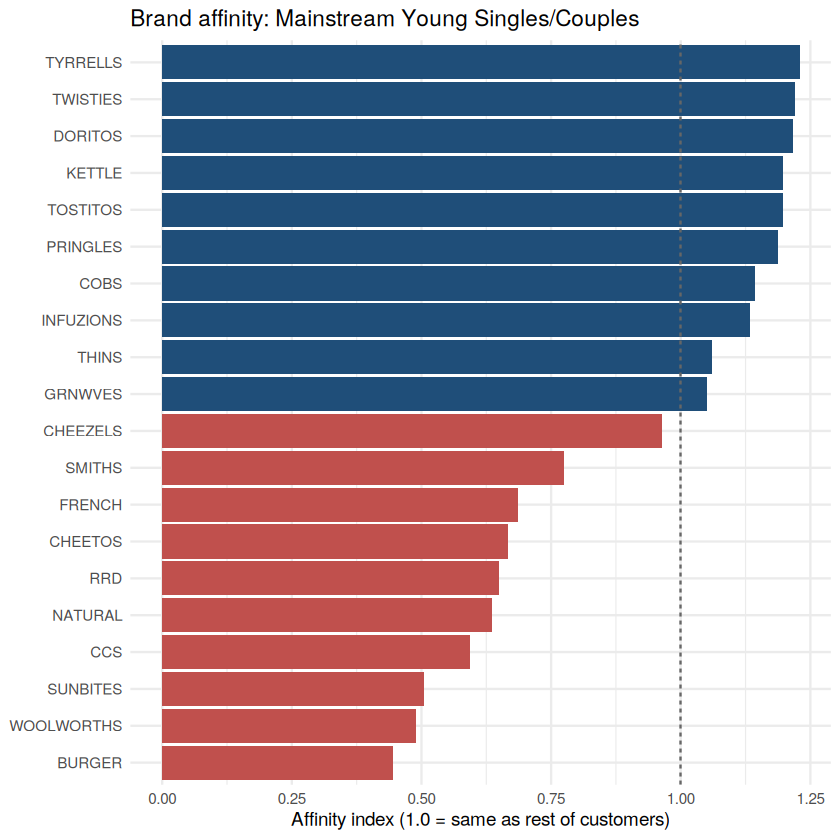

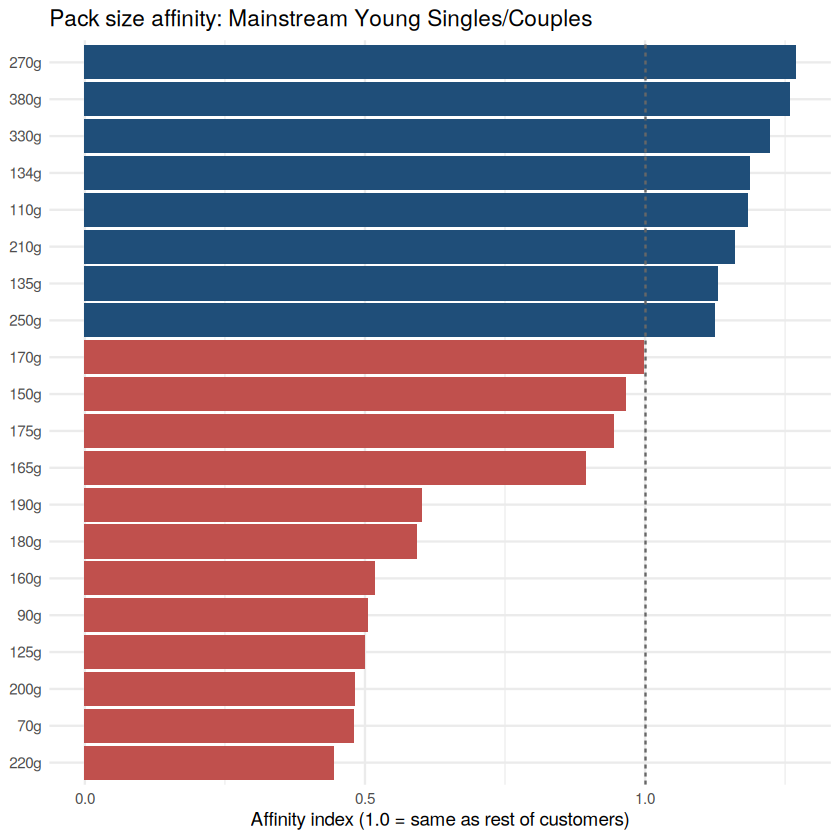

In [ ]:
b <- brand_aff %>% mutate(bar = if_else(affinity_index >= 1, "over", "under"))
p1 <- ggplot(b, aes(reorder(key, affinity_index), affinity_index, fill = bar)) +
  geom_col() + geom_hline(yintercept = 1, linetype = "dashed", colour = "grey40") +
  coord_flip() +
  scale_fill_manual(values = c(over = "#1f4e79", under = "#c0504d"), guide = "none") +
  labs(title = "Brand affinity: Mainstream Young Singles/Couples", x = NULL,
       y = "Affinity index (1.0 = same as rest of customers)")

pk <- pack_aff %>%
  mutate(label = paste0(key, "g"), bar = if_else(affinity_index >= 1, "over", "under"))
p2 <- ggplot(pk, aes(reorder(label, affinity_index), affinity_index, fill = bar)) +
  geom_col() + geom_hline(yintercept = 1, linetype = "dashed", colour = "grey40") +
  coord_flip() +
  scale_fill_manual(values = c(over = "#1f4e79", under = "#c0504d"), guide = "none") +
  labs(title = "Pack size affinity: Mainstream Young Singles/Couples", x = NULL,
       y = "Affinity index (1.0 = same as rest of customers)")

print(p1); print(p2)
ggsave("outputs/chart_06_affinity_brand.png", p1, width = 8, height = 7, dpi = 110)
ggsave("outputs/chart_06_affinity_pack.png", p2, width = 8, height = 7, dpi = 110)

**Brands.** Mainstream Young Singles/Couples over-index on Tyrrells, Twisties, Doritos, Kettle, Tostitos and Pringles, each around 1.2 times the rest of the base. They under-index on Woolworths (the private label), RRD, Natural, Smiths and Cheetos, which are at about 0.5 to 0.8.

**Pack sizes.** This segment buys the bigger packs more often than other customers: 270g, 380g and 330g are each about 1.2 to 1.3 times the rest of the base. The 175g and 150g packs, which are the category's most common sizes, are slightly below the average.

### 3.7 Are larger packs better value per gram?

Pack size only matters commercially if the larger packs are priced sensibly. Price per 100g is compared across pack sizes.

PACK_SIZE,units_share,price_per_100g
<int>,<dbl>,<dbl>
70,0.006,3.429
90,0.012,1.889
110,0.091,3.454
125,0.006,1.680
134,0.102,2.761
135,0.013,3.111
150,0.163,2.519
160,0.012,1.188
165,0.062,2.115


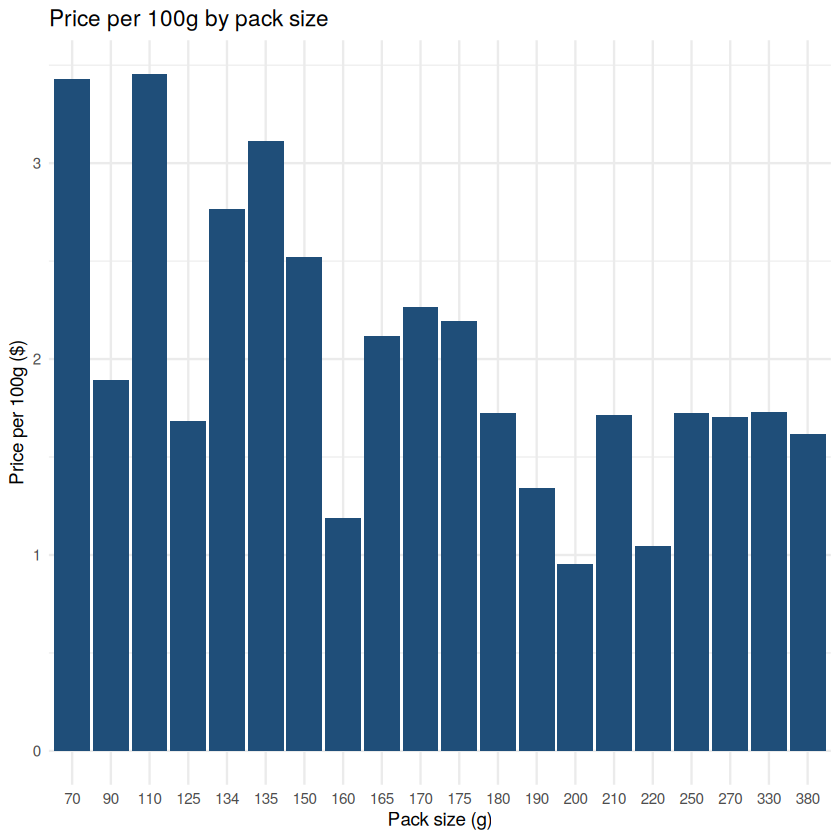

In [ ]:
pack_value <- data %>%
  group_by(PACK_SIZE) %>%
  summarise(sales = sum(TOT_SALES), units = sum(PROD_QTY), .groups = "drop") %>%
  mutate(price_per_100g = sales / (units * PACK_SIZE) * 100,
         units_share = units / sum(units))

p <- ggplot(pack_value, aes(factor(PACK_SIZE), price_per_100g)) +
  geom_col(fill = "#1f4e79") +
  labs(title = "Price per 100g by pack size", x = "Pack size (g)", y = "Price per 100g ($)")
print(p)
ggsave("outputs/chart_07_price_per_100g.png", p, width = 11, height = 4.5, dpi = 110)

pack_value %>%
  select(PACK_SIZE, units_share, price_per_100g) %>%
  mutate(across(where(is.double), ~ round(.x, 3)))

Small packs are the most expensive per gram. The 70g to 135g packs cost roughly $2.8 to $3.5 per 100g, against about $1.6 to $1.7 for the 250g to 380g packs. Larger packs therefore give better value per gram, which supports the Mainstream Young Singles/Couples preference for bigger packs. The pattern is not perfectly monotonic (the 200g and 220g packs are cheaper still), so pack choice should be checked product by product before it is used in a pricing decision.

In [ ]:
build_monthly_metrics <- function(df) {
  df %>%
    group_by(STORE_NBR, YEARMONTH) %>%
    summarise(
      totSales = sum(TOT_SALES),
      nCustomers = n_distinct(LYLTY_CARD_NBR),
      nTxn = n_distinct(TXN_ID),
      nChips = sum(PROD_QTY),
      .groups = "drop"
    ) %>%
    mutate(
      nTxnPerCust = nTxn / nCustomers,
      nChipsPerTxn = nChips / nTxn,
      avgPricePerUnit = totSales / nChips
    )
}

monthly <- build_monthly_metrics(data)
cat("Store-months:", nrow(monthly), "\n")
head(monthly)

Store-months: 3165 


STORE_NBR,YEARMONTH,totSales,nCustomers,nTxn,nChips,nTxnPerCust,nChipsPerTxn,avgPricePerUnit
<dbl>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,201807,188.9,47,49,58,1.042553,1.183673,3.256897
1,201808,168.4,41,41,52,1.000000,1.268293,3.238462
1,201809,268.1,57,59,71,1.035088,1.203390,3.776056
1,201810,175.4,39,40,51,1.025641,1.275000,3.439216
1,201811,184.8,44,45,55,1.022727,1.222222,3.360000
1,201812,160.6,37,40,48,1.081081,1.200000,3.345833


### 4.2 Eligible control stores

Only stores that trade for all twelve months can be compared fairly, so the pool is limited to those with a full year of data. The pre-trial period is July 2018 to January 2019, which is seven months.

In [ ]:
TRIAL_STORES  <- c(77, 86, 88)
PRE_TRIAL_END <- 201902          # trial starts Feb 2019; pre-trial is YEARMONTH < 201902
TRIAL_MONTHS  <- c(201902, 201903, 201904)

full_obs_stores <- monthly %>% count(STORE_NBR) %>% filter(n == 12) %>% pull(STORE_NBR)
pre_trial <- monthly %>% filter(YEARMONTH < PRE_TRIAL_END, STORE_NBR %in% full_obs_stores)

cat("Stores with 12 months of data:", length(full_obs_stores), "\n")
cat("Trial stores eligible:", TRIAL_STORES[TRIAL_STORES %in% full_obs_stores], "\n")
cat("Pre-trial months:", sort(unique(pre_trial$YEARMONTH)), "\n")

Stores with 12 months of data: 259 


Trial stores eligible: 77 86 88 


Pre-trial months: 201807 201808 201809 201810 201811 201812 201901 


### 4.3 Measures of similarity

Two measures rank each candidate control store against a trial store, both on the pre-trial months only.

- **Correlation** asks whether the two stores move up and down together month to month.
- **Magnitude distance** asks whether the sizes are similar. The absolute gap in each month is rescaled to 0 to 1 across the candidate stores, so 1 means the closest store that month and 0 means the furthest. The trial store itself is excluded from the scaling, which avoids a zero distance pulling the minimum down.

Both functions take the same inputs so they can be reused for each trial store.

In [ ]:
wide_metric <- function(input_table, metric_col) {
  input_table %>%
    select(YEARMONTH, STORE_NBR, value = all_of(metric_col)) %>%
    pivot_wider(names_from = STORE_NBR, values_from = value) %>%
    arrange(YEARMONTH)
}

calculate_correlation <- function(input_table, metric_col, store_comparison) {
  w <- wide_metric(input_table, metric_col)
  trial_x <- w[[as.character(store_comparison)]]
  cands <- setdiff(names(w), c("YEARMONTH", as.character(store_comparison)))
  tibble(
    Store1 = store_comparison,
    Store2 = as.numeric(cands),
    corr_measure = map_dbl(cands, ~ cor(trial_x, w[[.x]]))
  )
}

calculate_magnitude_distance <- function(input_table, metric_col, store_comparison) {
  w <- wide_metric(input_table, metric_col)
  trial_x <- w[[as.character(store_comparison)]]
  cands <- setdiff(names(w), c("YEARMONTH", as.character(store_comparison)))
  # months x candidate stores: absolute gap to the trial store in each month
  diff_m <- sapply(cands, function(s) abs(w[[s]] - trial_x))
  if (!is.matrix(diff_m)) diff_m <- matrix(diff_m, ncol = length(cands))
  mn <- apply(diff_m, 1, min)
  mx <- apply(diff_m, 1, max)
  mag <- 1 - (diff_m - mn) / (mx - mn)
  tibble(
    Store1 = store_comparison,
    Store2 = as.numeric(cands),
    mag_measure = colMeans(mag)
  )
}

rank_control_stores <- function(input_table, trial_store, corr_weight = 0.5) {
  scores <- NULL
  for (metric in c("totSales", "nCustomers")) {
    c_tbl <- calculate_correlation(input_table, metric, trial_store)
    m_tbl <- calculate_magnitude_distance(input_table, metric, trial_store)
    s <- c_tbl %>%
      inner_join(m_tbl, by = c("Store1", "Store2")) %>%
      mutate(!!paste0("score_", metric) := corr_weight * corr_measure + (1 - corr_weight) * mag_measure) %>%
      select(Store1, Store2, starts_with("score_"))
    scores <- if (is.null(scores)) s else inner_join(scores, s, by = c("Store1", "Store2"))
  }
  scores %>%
    mutate(final_score = 0.5 * score_totSales + 0.5 * score_nCustomers) %>%
    arrange(desc(final_score))
}

### 4.4 Select the control stores

Each trial store is ranked against every eligible store, and the highest-scoring store is taken as its control. The final score averages the sales and customer scores equally.

In [ ]:
rankings <- list()
controls <- integer(0)
for (trial in TRIAL_STORES) {
  r <- rank_control_stores(pre_trial, trial)
  rankings[[as.character(trial)]] <- r
  controls[as.character(trial)] <- as.integer(r$Store2[1])
  cat("Trial store", trial, ": top five candidates\n")
  print(head(r, 5) %>% mutate(across(where(is.double), ~ round(.x, 4))))
  cat("\n")
}
cat("Selected control stores:\n")
print(controls)

Trial store 77 : top five candidates
# A tibble: 5 × 5
  Store1 Store2 score_totSales score_nCustomers final_score
   <dbl>  <dbl>          <dbl>            <dbl>       <dbl>
1     77    233          0.980            0.978       0.979
2     77     50          0.937            0.821       0.879
3     77     35          0.800            0.896       0.848
4     77    254          0.754            0.916       0.834
5     77     84          0.748            0.887       0.818

Trial store 86 : top five candidates
# A tibble: 5 × 5
  Store1 Store2 score_totSales score_nCustomers final_score
   <dbl>  <dbl>          <dbl>            <dbl>       <dbl>
1     86    155          0.916            0.901       0.908
2     86    114          0.844            0.905       0.875
3     86    138          0.872            0.777       0.824
4     86     56          0.771            0.750       0.761
5     86    128          0.771            0.727       0.749

Trial store 88 : top five candidates
# A tibble:

Selected control stores:


 77  86  88 
233 155 237 


The selected controls are store 233 for trial store 77, store 155 for trial store 86 and store 237 for trial store 88. Store 77's best match is very strong (0.98) and clearly ahead of the next candidate. Store 86's lead is narrower (0.91 against 0.87), and store 88's best match is weaker (0.75), so the store 88 control is the one to treat with most caution.

### 4.5 Visual check before the trial

Before judging the trial, the trial store, its control and the average of all other stores are plotted over the pre-trial months. A good control should track the trial store closely, not just match its average level.

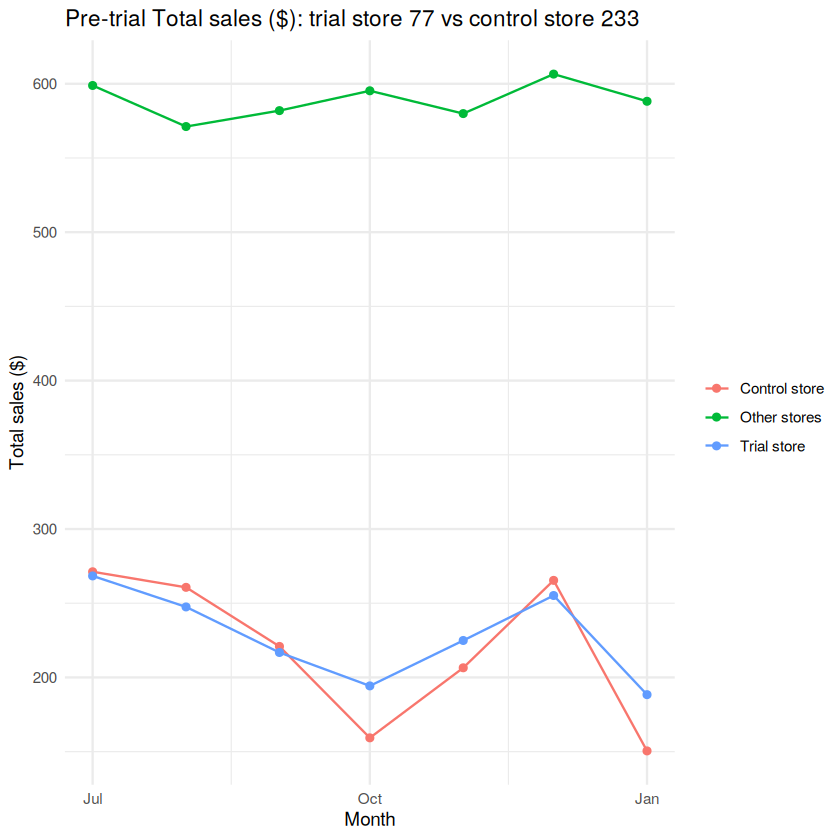

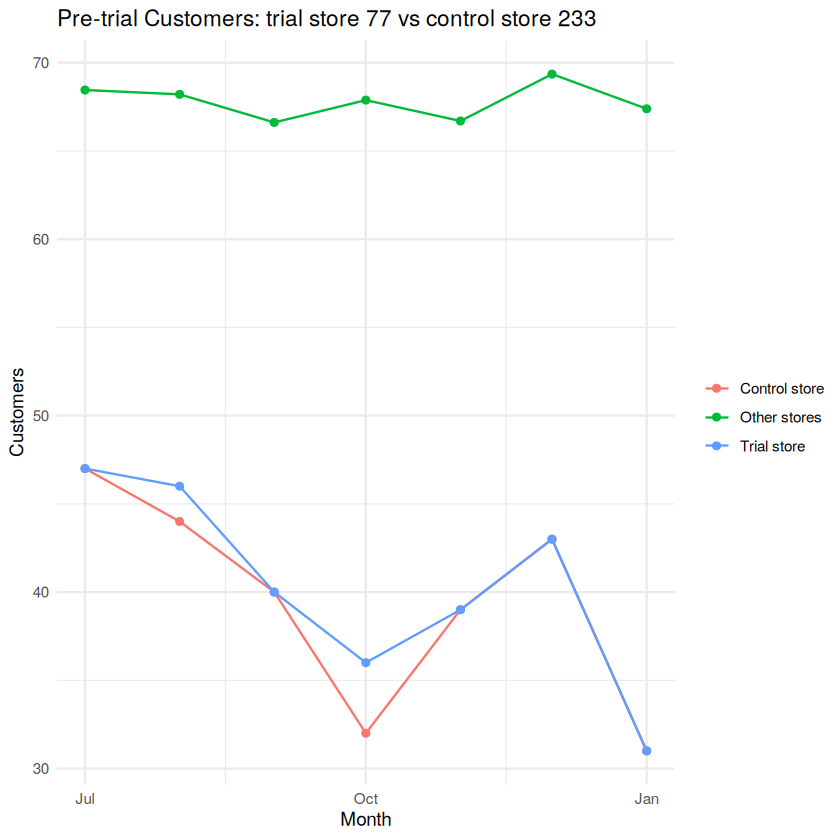

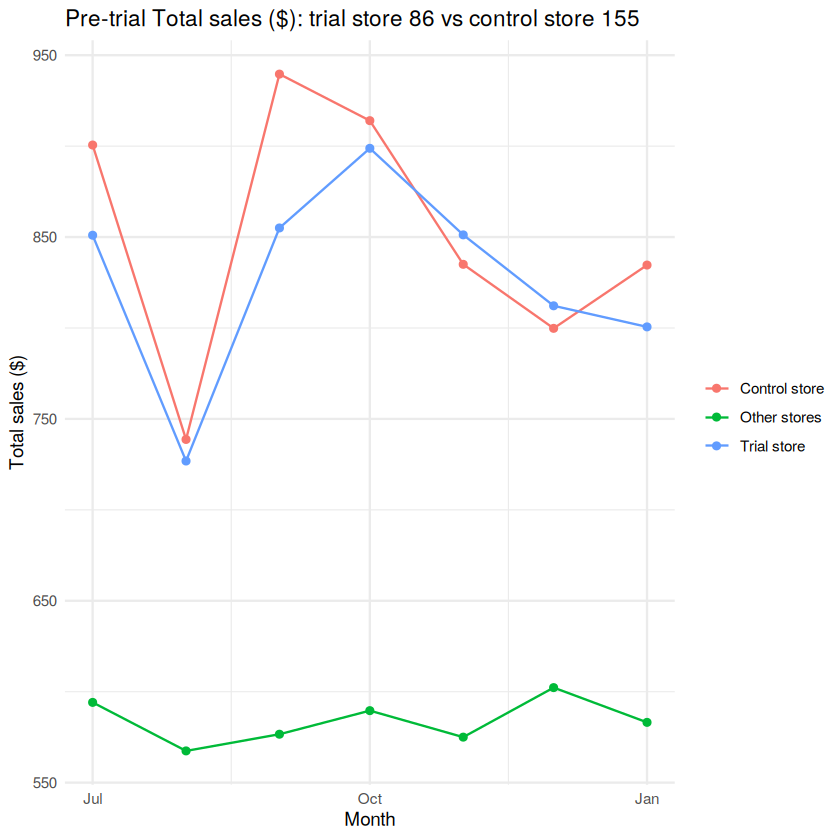

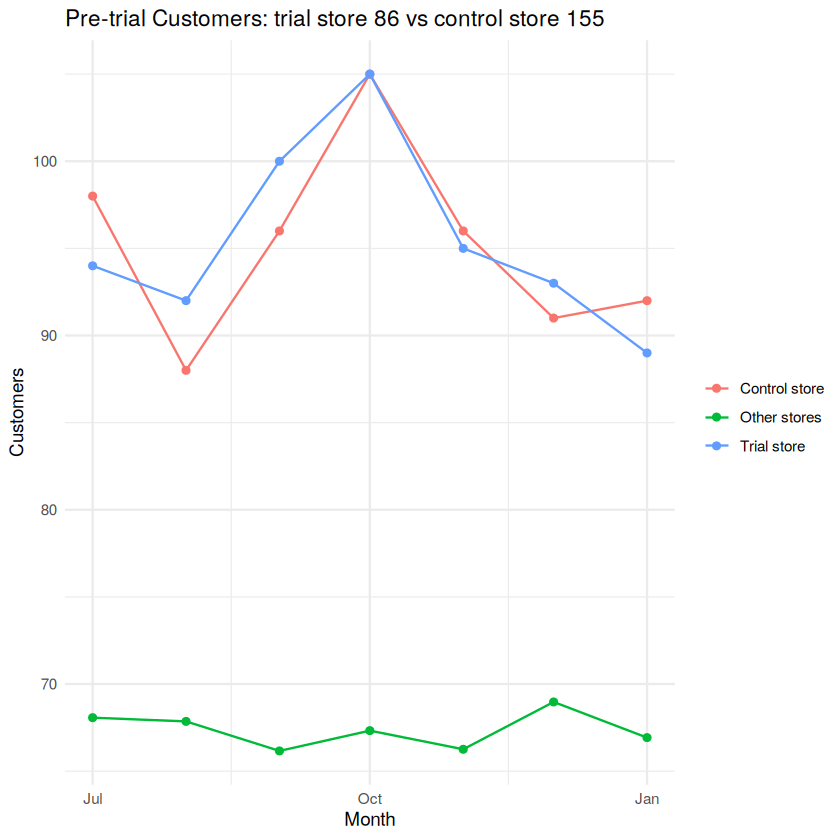

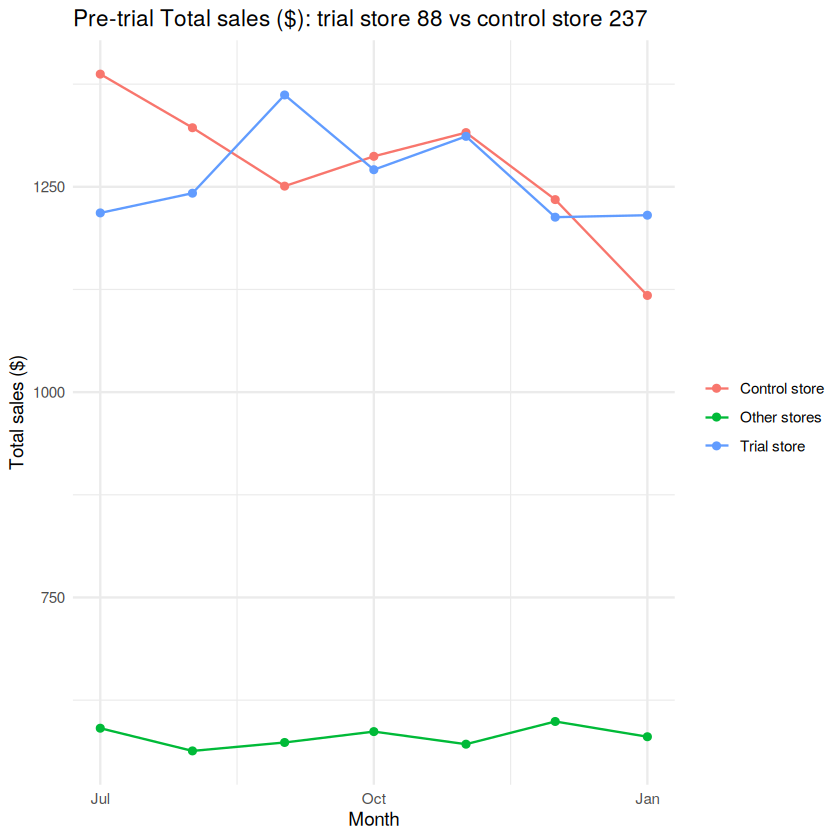

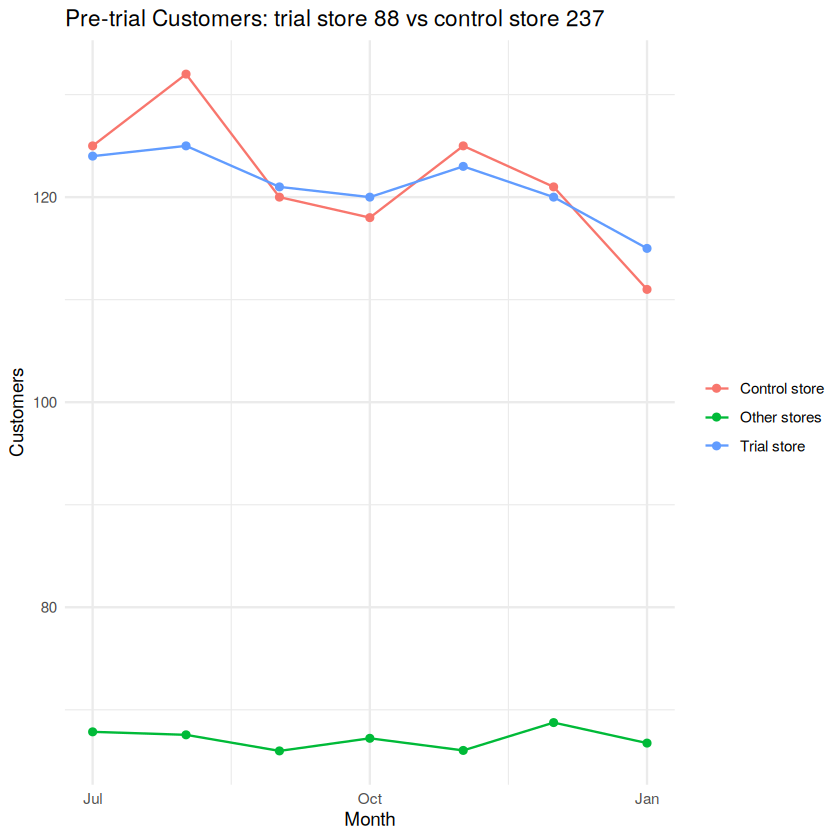

In [ ]:
plot_pre_trial <- function(monthly_df, trial, control, metric, ylabel) {
  d <- monthly_df %>%
    filter(YEARMONTH < PRE_TRIAL_END) %>%
    mutate(group = case_when(
      STORE_NBR == trial ~ "Trial store",
      STORE_NBR == control ~ "Control store",
      TRUE ~ "Other stores"
    )) %>%
    group_by(YEARMONTH, group) %>%
    summarise(value = mean(.data[[metric]]), .groups = "drop") %>%
    mutate(month = to_date(YEARMONTH))

  ggplot(d, aes(month, value, colour = group)) +
    geom_line() + geom_point() +
    labs(title = paste0("Pre-trial ", ylabel, ": trial store ", trial, " vs control store ", control),
         x = "Month", y = ylabel, colour = NULL)
}

for (trial in TRIAL_STORES) {
  for (m in c("totSales", "nCustomers")) {
    ylab <- if (m == "totSales") "Total sales ($)" else "Customers"
    p <- plot_pre_trial(monthly %>% filter(STORE_NBR %in% full_obs_stores),
                        trial, controls[as.character(trial)], m, ylab)
    print(p)
    ggsave(paste0("outputs/chart_pre_trial_", m, "_store", trial, ".png"), p, width = 10, height = 4.5, dpi = 110)
  }
}

Before the trial, the control stores move in the same direction as the trial stores in most months, and the average of other stores sits in a different range. Store 86 and its control track each other closely. Store 77's control diverges in January 2019, when the control's sales fall sharply while the trial store's hold up, so it is a weaker match than the ranking alone suggests. Store 88's control is a less close match on the sales measure, as the ranking in section 4.4 showed.

### 4.6 Assess each trial

The control store's sales and customers are first scaled so that its pre-trial total matches the trial store's pre-trial total. Each trial month is then compared with the scaled control, giving a percentage difference.

The pre-trial percentage differences give a baseline for normal variation. The standard deviation of those differences is used to compute a t-value for each trial month. Pre-trial has seven months, so the standard deviation has six degrees of freedom and the one-sided 95% critical t-value is about 1.94. The template uses 7 degrees of freedom, which assumes eight pre-trial months; with seven months the threshold is slightly higher and the conclusions below hold under either value.

The 5th and 95th percentile band is approximated as plus or minus two standard deviations around the scaled control, as in the template. It is an approximation of the 5th to 95th percentile range rather than an exact interval, and it is drawn around the scaled control so it lines up with the control line in the charts.

In [ ]:
assess_trial <- function(monthly_df, trial, control, metric) {
  t_df <- monthly_df %>% filter(STORE_NBR == trial) %>% arrange(YEARMONTH)
  c_df <- monthly_df %>% filter(STORE_NBR == control) %>% arrange(YEARMONTH)

  pre <- t_df$YEARMONTH < PRE_TRIAL_END
  scale <- sum(t_df[[metric]][pre]) / sum(c_df[[metric]][pre])
  c_scaled <- c_df[[metric]] * scale
  pct <- (t_df[[metric]] - c_scaled) / c_scaled

  sd_pct <- sd(pct[pre])
  dof <- sum(pre) - 1
  t_crit <- qt(0.95, dof)

  out <- tibble(
    YEARMONTH = t_df$YEARMONTH,
    month = to_date(t_df$YEARMONTH),
    trial = t_df[[metric]],
    control_scaled = c_scaled,
    pct_diff = pct,
    t_value = pct / sd_pct,
    upper_95 = c_scaled * (1 + 2 * sd_pct),
    lower_5 = c_scaled * (1 - 2 * sd_pct)
  ) %>%
    mutate(significant_uplift = t_value > t_crit & YEARMONTH %in% TRIAL_MONTHS)

  list(data = out, sd = sd_pct, dof = dof, t_crit = t_crit, scale = scale)
}

plot_trial <- function(trial, control, ylabel, a, fname) {
  plot_df <- bind_rows(
    tibble(month = a$month, value = a$trial, series = paste("Trial store", trial)),
    tibble(month = a$month, value = a$control_scaled, series = paste0("Control store ", control, " (scaled)"))
  )
  p <- ggplot() +
    annotate("rect", xmin = as.Date("2019-02-01"), xmax = as.Date("2019-04-30"),
             ymin = -Inf, ymax = Inf, fill = "#f2dcdb", alpha = 0.6) +
    geom_line(data = plot_df, aes(month, value, colour = series)) +
    geom_point(data = plot_df, aes(month, value, colour = series)) +
    geom_line(data = a, aes(month, upper_95), linetype = "dashed", colour = "grey50") +
    geom_line(data = a, aes(month, lower_5), linetype = "dashed", colour = "grey50") +
    labs(title = paste0("Trial store ", trial, " vs control store ", control, ": ", ylabel),
         subtitle = "Shaded: trial period. Dashed: control +/- 2 SD band",
         x = "Month", y = ylabel, colour = NULL)
  print(p)
  ggsave(fname, p, width = 10, height = 4.8, dpi = 110)
}

assessments <- list()
for (trial in TRIAL_STORES) {
  for (m in c("totSales", "nCustomers")) {
    assessments[[paste(trial, m, sep = "_")]] <-
      assess_trial(monthly, trial, controls[as.character(trial)], m)
  }
}

In [ ]:
for (trial in TRIAL_STORES) {
  a <- assessments[[paste(trial, "totSales", sep = "_")]]
  cat(sprintf("Trial store %d, control %d: sd of pre-trial %% diff = %.4f, df = %d, t critical = %.3f\n",
              trial, controls[as.character(trial)], a$sd, a$dof, a$t_crit))
  a$data %>%
    filter(YEARMONTH %in% TRIAL_MONTHS) %>%
    select(YEARMONTH, trial, control_scaled, pct_diff, t_value, significant_uplift) %>%
    mutate(across(where(is.double), ~ round(.x, 3))) %>%
    print()
  cat("\n")
}

Trial store 77, control 233: sd of pre-trial % diff = 0.1217, df = 6, t critical = 1.943
# A tibble: 3 × 6
  YEARMONTH trial control_scaled pct_diff t_value significant_uplift
      <int> <dbl>          <dbl>    <dbl>   <dbl> <lgl>             
1    201902  212.           229.   -0.078   -0.64 FALSE             
2    201903  255.           188.    0.359    2.94 TRUE              
3    201904  258.           150.    0.721    5.93 TRUE              

Trial store 86, control 155: sd of pre-trial % diff = 0.0401, df = 6, t critical = 1.943
# A tibble: 3 × 6
  YEARMONTH trial control_scaled pct_diff t_value significant_uplift
      <int> <dbl>          <dbl>    <dbl>   <dbl> <lgl>             
1    201902  873.           827.    0.055   1.38  FALSE             
2    201903  945.           746.    0.268   6.68  TRUE              
3    201904  804            778.    0.033   0.832 FALSE             

Trial store 88, control 237: sd of pre-trial % diff = 0.0763, df = 6, t critical = 1.943
# A t

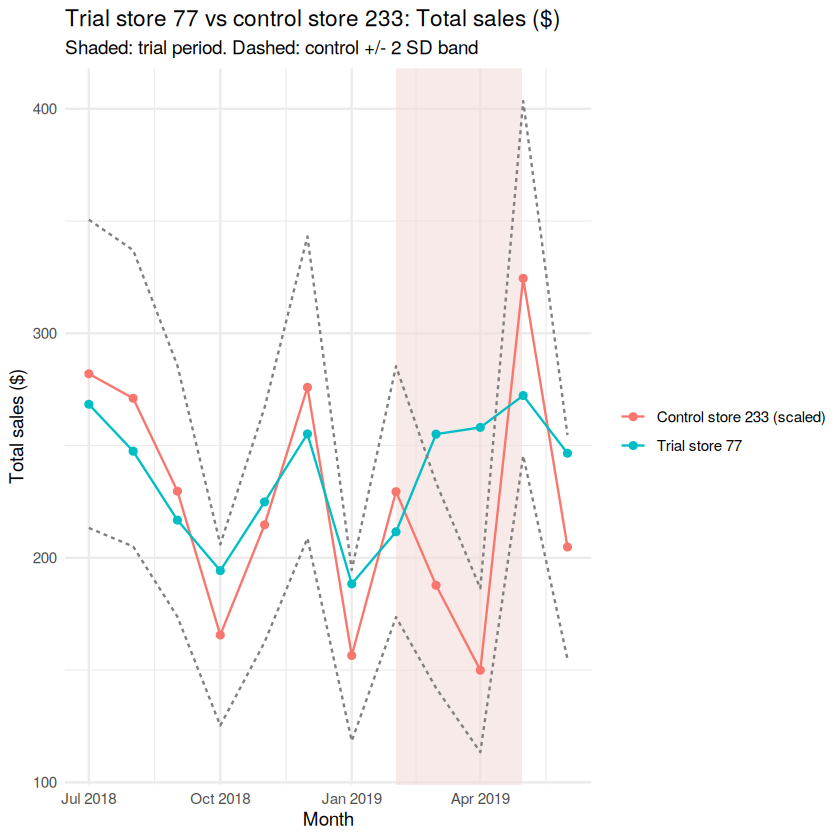

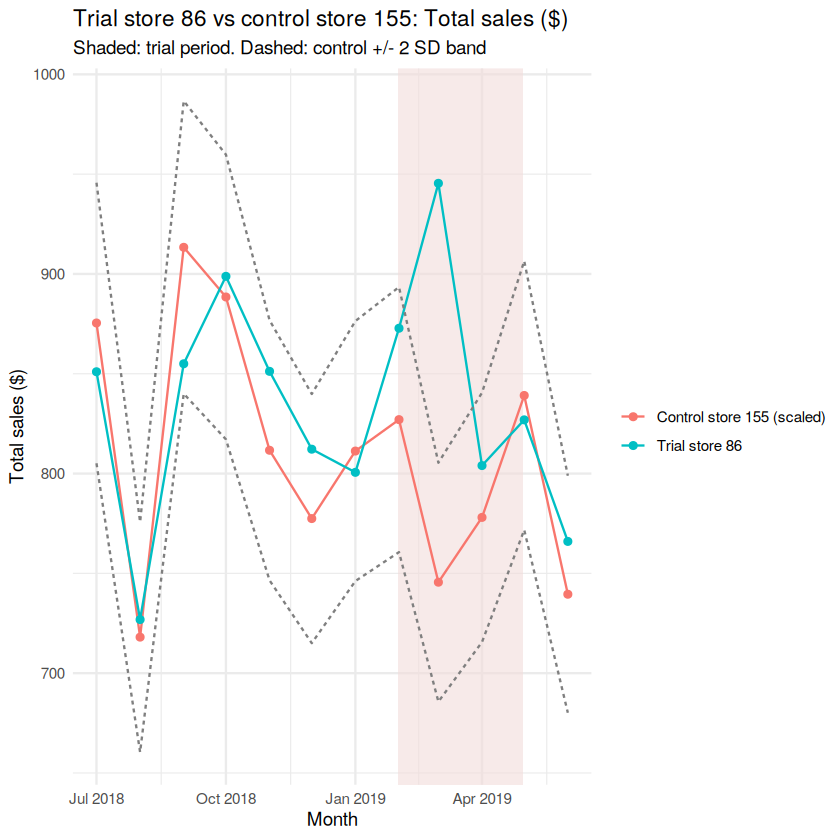

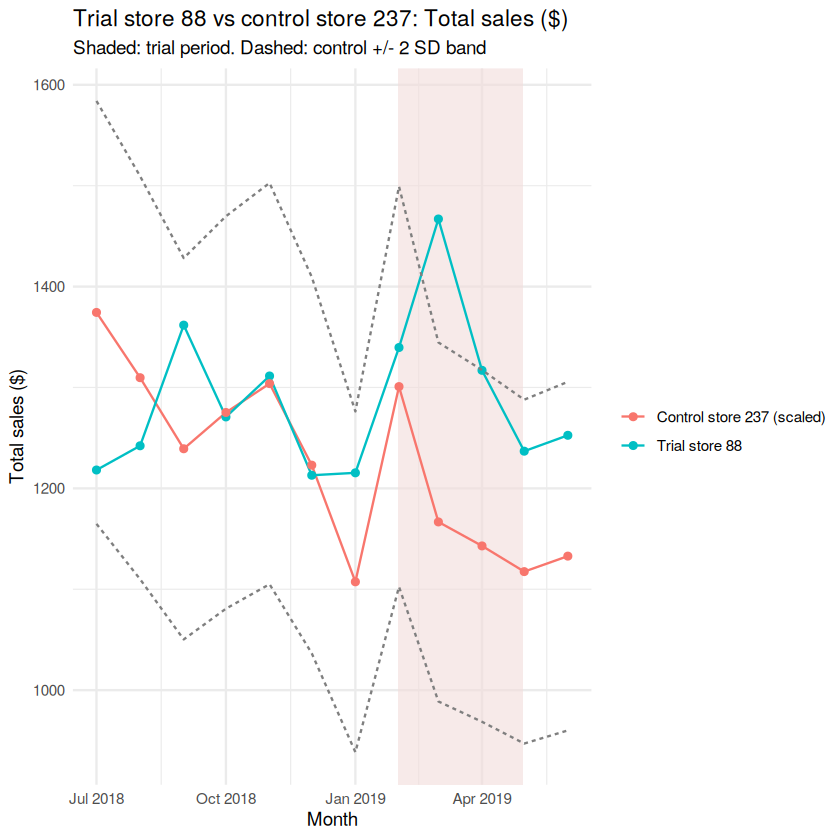

In [ ]:
for (trial in TRIAL_STORES) {
  plot_trial(trial, controls[as.character(trial)], "Total sales ($)",
             assessments[[paste(trial, "totSales", sep = "_")]]$data,
             paste0("outputs/chart_trial_sales_store", trial, ".png"))
}

### 4.7 Customers, not just sales

The sales test is repeated for customer numbers. Doing the same test for customers shows whether any uplift comes from more shoppers or from the same shoppers spending more.

Trial store 77: customers, t-values and significance
# A tibble: 3 × 6
  YEARMONTH trial control_scaled pct_diff t_value significant_uplift
      <int> <int>          <dbl>    <dbl>   <dbl> <lgl>             
1    201902    40           42.9   -0.068   -1.46 FALSE             
2    201903    46           35.8    0.286    6.16 TRUE              
3    201904    47           27.6    0.704   15.1  TRUE              

Trial store 86: customers, t-values and significance
# A tibble: 3 × 6
  YEARMONTH trial control_scaled pct_diff t_value significant_uplift
      <int> <int>          <dbl>    <dbl>   <dbl> <lgl>             
1    201902   105           92.3    0.138    4.04 TRUE              
2    201903   108           91.3    0.183    5.37 TRUE              
3    201904    99           93.3    0.061    1.80 FALSE             

Trial store 88: customers, t-values and significance
# A tibble: 3 × 6
  YEARMONTH trial control_scaled pct_diff t_value significant_uplift
      <int> <int>         

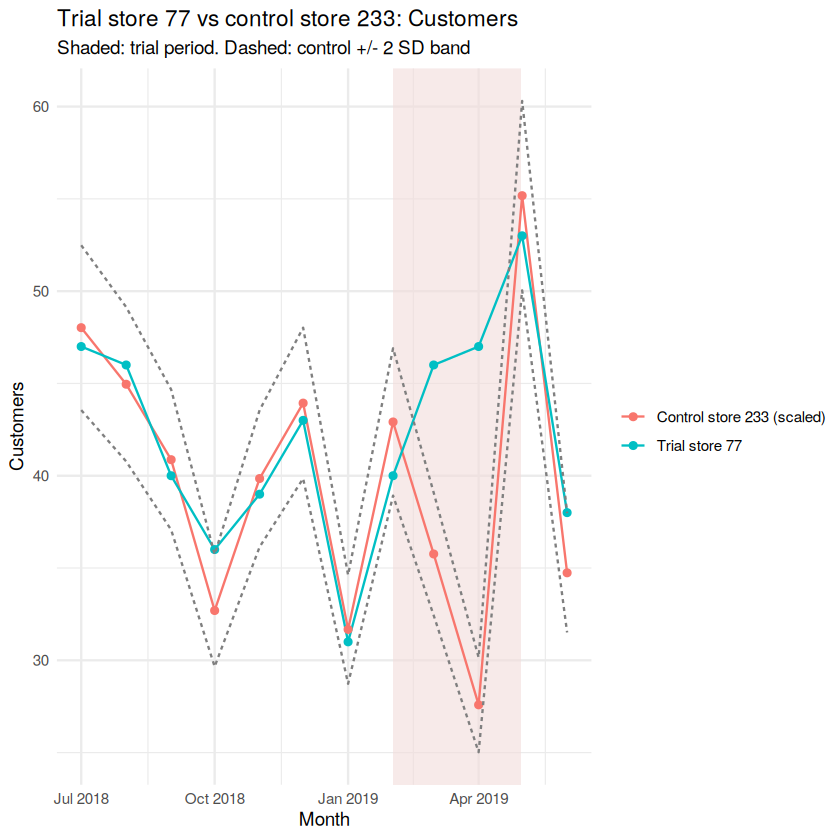

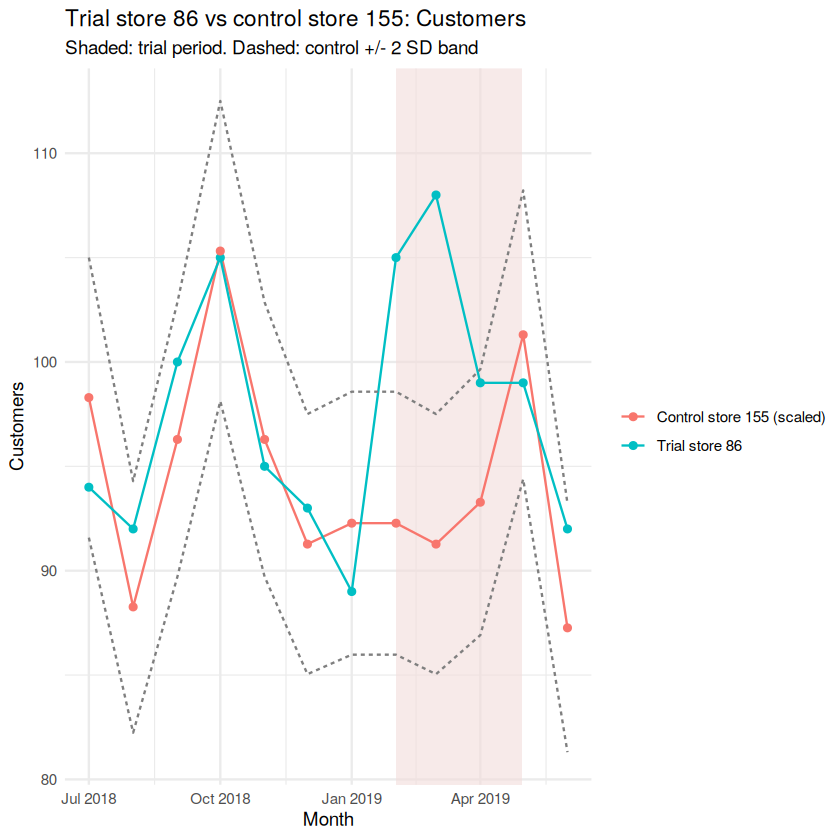

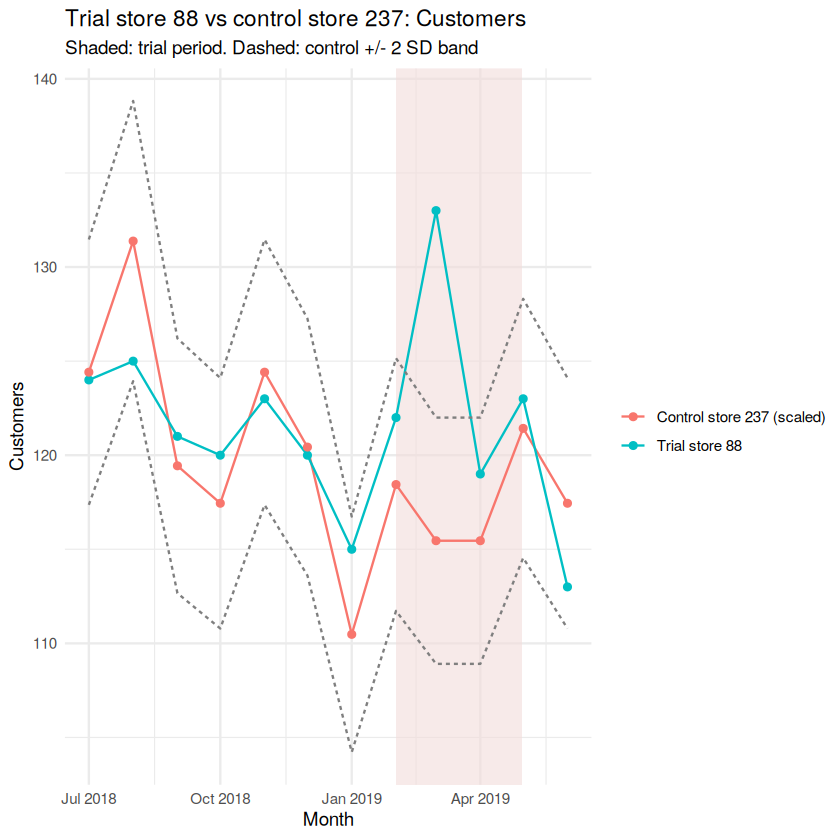

In [ ]:
for (trial in TRIAL_STORES) {
  a <- assessments[[paste(trial, "nCustomers", sep = "_")]]
  cat(sprintf("Trial store %d: customers, t-values and significance\n", trial))
  a$data %>%
    filter(YEARMONTH %in% TRIAL_MONTHS) %>%
    select(YEARMONTH, trial, control_scaled, pct_diff, t_value, significant_uplift) %>%
    mutate(across(where(is.double), ~ round(.x, 3))) %>%
    print()
  cat("\n")
}

for (trial in TRIAL_STORES) {
  plot_trial(trial, controls[as.character(trial)], "Customers",
             assessments[[paste(trial, "nCustomers", sep = "_")]]$data,
             paste0("outputs/chart_trial_customers_store", trial, ".png"))
}

### 4.8 Summary of the trial results

The table below gives the sales uplift over the three trial months against the scaled control, with whether each month passed the test. The pre-trial sd and degrees of freedom are reported alongside.

In [ ]:
summary_tbl <- map(TRIAL_STORES, function(trial) {
  s_obj <- assessments[[paste(trial, "totSales", sep = "_")]]
  c_obj <- assessments[[paste(trial, "nCustomers", sep = "_")]]
  tp <- s_obj$data %>% filter(YEARMONTH %in% TRIAL_MONTHS)
  cm <- c_obj$data %>% filter(YEARMONTH %in% TRIAL_MONTHS)

  uplift <- sum(tp$trial) / sum(tp$control_scaled) - 1
  sig_s <- tp$YEARMONTH[tp$significant_uplift]
  sig_c <- cm$YEARMONTH[cm$t_value > c_obj$t_crit]

  tibble(
    trial_store = trial,
    control_store = unname(controls[as.character(trial)]),
    `trial_sales_uplift_%` = round(100 * uplift, 1),
    sig_months_sales = if (length(sig_s)) paste(sig_s, collapse = ", ") else "none",
    sig_months_customers = if (length(sig_c)) paste(sig_c, collapse = ", ") else "none"
  )
}) %>% bind_rows()
summary_tbl

trial_store,control_store,trial_sales_uplift_%,sig_months_sales,sig_months_customers
<dbl>,<int>,<dbl>,<chr>,<chr>
77,233,27.8,"201903, 201904","201903, 201904"
86,155,11.6,201903,"201902, 201903"
88,237,14.2,"201903, 201904",201903


### 4.9 What drove the change?

Sales are the product of customers, transactions per customer, chips per transaction and price per pack. To find which one moved, the trial store's change from its own pre-trial average is compared with the same change in its control store. The relative difference is the trial's effect on that driver.

In [ ]:
driver_cols <- c("nCustomers", "nTxnPerCust", "nChipsPerTxn", "avgPricePerUnit")

driver_effect <- function(trial, control) {
  avg <- monthly %>%
    filter(STORE_NBR %in% c(trial, control), YEARMONTH <= 201904) %>%
    mutate(period = if_else(YEARMONTH < PRE_TRIAL_END, "pre", "trial")) %>%
    group_by(STORE_NBR, period) %>%
    summarise(across(all_of(driver_cols), mean), .groups = "drop")

  growth <- function(store) {
    p <- avg %>% filter(STORE_NBR == store, period == "pre") %>% select(all_of(driver_cols)) %>% unlist()
    t <- avg %>% filter(STORE_NBR == store, period == "trial") %>% select(all_of(driver_cols)) %>% unlist()
    unname(t / p - 1)
  }

  t_g <- growth(trial)
  c_g <- growth(control)
  tibble(
    driver = driver_cols,
    `trial_change_%` = round(100 * t_g, 1),
    `control_change_%` = round(100 * c_g, 1),
    `relative_effect_%` = round(100 * ((1 + t_g) / (1 + c_g) - 1), 1)
  )
}

for (trial in TRIAL_STORES) {
  cat("Trial store", trial, "vs control", controls[as.character(trial)],
      "(relative effect = trial change vs control change)\n")
  print(driver_effect(trial, controls[as.character(trial)]))
  cat("\n")
}

Trial store 77 vs control 233 (relative effect = trial change vs control change)
# A tibble: 4 × 4
  driver          `trial_change_%` `control_change_%` `relative_effect_%`
  <chr>                      <dbl>              <dbl>               <dbl>
1 nCustomers                  10                -12.1                25.2
2 nTxnPerCust                 -1.9               -0.1                -1.8
3 nChipsPerTxn                 4.7               -4.1                 9.2
4 avgPricePerUnit             -6.6               -0.5                -6.2

Trial store 86 vs control 155 (relative effect = trial change vs control change)
# A tibble: 4 × 4
  driver          `trial_change_%` `control_change_%` `relative_effect_%`
  <chr>                      <dbl>              <dbl>               <dbl>
1 nCustomers                   9                 -3.3                12.7
2 nTxnPerCust                 -2.7               -2.5                -0.2
3 nChipsPerTxn                 0.7                1.4        

## 5. Findings and recommendations (Task 3)

The report leads with the answer, then gives the evidence in the order the client needs it. The findings below follow that order.

**Answer.** Stores 77 and 88 both showed sales uplift in March and April 2019 that is larger than normal month-to-month variation, with store 77 the stronger of the two. Store 86 showed a significant gain in March only. Across the three trial months, sales were about 28% higher than the scaled control in store 77, about 14% higher in store 88 and about 12% higher in store 86. Roll the layout out selectively, starting with stores that look like 77 and 88, and keep measuring store 86 before deciding on it.

**Supporting findings**

1. **Chip spend is spread across segments, but two groups stand out.** Older Families (Budget) is the largest segment by sales, and Young Singles/Couples (Mainstream) is the largest by buyers and the highest price per pack. Both are worth targeting, for different reasons.
2. **Families buy in volume.** Older and Young Families take about nine packs per customer, roughly double the Young Singles/Couples. Promotions that encourage multipacks or larger packs suit this segment.
3. **Mainstream Young Singles/Couples pay a higher price and prefer the bigger brands and packs.** They over-index on Kettle, Doritos, Pringles and Tyrrells, and on 270g, 330g and 380g packs. Larger packs also give better value per gram, so the message is value as well as range.
4. **The trial layout worked in stores 77 and 88 and was weaker in 86.** Store 77's uplift came mainly from more customers (about 25% above its control), with slightly more chips per transaction and a lower price per pack. Store 88's uplift was split between more customers and more visits per customer. Store 86's gain was significant in March only, and it was driven by more customers.
**Recommendations**

- **Roll out the layout to stores similar to 77 and 88.** Both show sustained uplift across two months, which is the more reliable signal.
- **Keep store 86 under observation before deciding.** Its gain was concentrated in March, so it may reflect a one-off rather than a durable effect.
- **Target Mainstream Young Singles/Couples with the premium brands and bigger packs they already buy.** Shelf placement and range in the Kettle, Doritos, Pringles and Tyrrells lines is the obvious lever.
- **Use multipack and large-pack promotions for family segments.** Their spend is driven by basket size, so the commercial lever is units per visit rather than customer acquisition.

**Caveats**

- The trial ran for three months, so the results may partly reflect novelty. A longer test would confirm durability.
- Each trial store has one control store, and the comparison uses fewer than 150 customers a month. Individual months are noisy, so the results are indicative rather than conclusive.
- Store 88's control is the weakest match of the three (final score 0.75), so its uplift should be read with more caution than store 77's.
- The data covers only loyalty card holders and does not include promotions, price changes or shelf-level detail. Those would sharpen the explanation of the store 77 price drop and the store 86 pattern.
- The analysis covers chips only, so it cannot show whether chip spend is incremental to the store's total grocery spend.